In [6]:
from pathlib import Path
import pandas as pd

print("CWD actual:", Path.cwd())
print("CWD es la raíz del proyecto:", (Path.cwd() / "src").exists())
print()

RAW = Path("data/raw")
print(f"¿Existe {RAW}?: {RAW.exists()}")
if RAW.exists():
    print(f"\nTotal archivos: {len(list(RAW.iterdir()))}")

    print("\n--- Archivos que contienen 'ipc' (case-insensitive) ---")
    for f in sorted(RAW.iterdir()):
        if "ipc" in f.name.lower():
            print(f"  {f.name}  ({f.stat().st_size:,} bytes)")

    print("\n--- Todos los .xls / .xlsx ---")
    for f in sorted(RAW.iterdir()):
        if f.suffix.lower() in (".xls", ".xlsx"):
            print(f"  {f.name}")

CWD actual: c:\Users\HP\Documents\Economy\economia_c
CWD es la raíz del proyecto: True

¿Existe data\raw?: True

Total archivos: 35

--- Archivos que contienen 'ipc' (case-insensitive) ---
  Series_IPC_Provinciales_webversion.xlsx  (64,333 bytes)
  sh_ipc_09_26.xls  (2,380,800 bytes)
  sh_ipc_aperturas.xls  (1,246,720 bytes)
  sh_ipc_precios_promedio.xls  (205,312 bytes)

--- Todos los .xls / .xlsx ---
  actividad_ied.xlsx
  cuadros_tic_05_25.xls
  Internet Accesos Tecnologias Provincias.xlsx
  nacional_serie_empleo_trimestral_7.xlsx
  nacional_serie_empresas_2.xlsx
  provinciales_serie_empleo_anual_3.xlsx
  provinciales_serie_empleo_trimestral_2dig_6.xlsx
  provinciales_serie_empleo_trimestral_4dig_7.xlsx
  provinciales_serie_empresas.xlsx
  provinciales_serie_empresas1_2.xlsx
  provinciales_serie_empresas2_2.xlsx
  provinciales_serie_empresas3_2.xlsx
  provinciales_serie_remuneraciones_anual_3.xlsx
  provinciales_serie_remuneraciones_mensual_2dig_8.xlsx
  provinciales_serie_remunerac

In [7]:
import pandas as pd
from pathlib import Path

# Confirmar CWD
print("CWD:", Path.cwd())

path = Path("data/raw/sh_ipc_09_26.xls")
print("Existe:", path.exists())

if path.exists():
    df = pd.read_excel(path,
                       sheet_name="Variación mensual IPC Nacional",
                       header=None)
    print("Filas:", df.shape[0])
    print("Columnas:", df.shape[1])
    print()
    print(df.head(12).to_string())
else:
    # Listar archivos IPC disponibles
    print("\nArchivos IPC en data/raw:")
    for f in sorted(Path("data/raw").glob("*ipc*")):
        print(" ", f.name)
        

CWD: c:\Users\HP\Documents\Economy\economia_c
Existe: True
Filas: 216
Columnas: 117

                                                                                                                                                                           0                    1                    2                    3                    4                    5                    6                    7                    8                    9                    10                   11                   12                   13                   14                   15                   16                   17                   18                   19                   20                   21                   22                   23                   24                   25                   26                   27                   28                   29                   30                   31                   32                   33                   34                   35       

In [8]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import pandas as pd

# --- 1) Localizar el archivo IPC ---
from src.config import FILE_IPC   # ruta absoluta de tu proyecto
print("FILE_IPC:", FILE_IPC)
print("Existe:", FILE_IPC.exists())

if not FILE_IPC.exists():
    print("\n⚠️  No existe. Buscando alternativas en data/raw/:")
    for f in sorted(Path("data/raw").iterdir()):
        if "ipc" in f.name.lower():
            print("  ", f.name)
    raise SystemExit("Corregí FILE_IPC en src/config.py o ajustá el nombre acá.")

# --- 2) Ver hojas disponibles ---
xl = pd.ExcelFile(FILE_IPC)
print("\nHojas:", xl.sheet_names)

# --- 3) Cargar la hoja que tenías pensada ---
sheet = "Variación mensual IPC Nacional"
if sheet in xl.sheet_names:
    df = pd.read_excel(FILE_IPC, sheet_name=sheet, header=None)
    print(f"\nHoja '{sheet}': shape={df.shape}")

    # --- 4) Buscar bloques regionales (NOA, etc.) ---
    print("\n--- Valores en columna 0 ---")
    for i in range(len(df)):
        val = str(df.iloc[i, 0]).strip()
        if val and val != "nan":
            print(f"Fila {i:3d}: {val}")
else:
    print(f"\n⚠️  Hoja '{sheet}' no existe. Elegí una de: {xl.sheet_names}")
    # Cargar la primera por defecto para que df exista
    df = pd.read_excel(FILE_IPC, sheet_name=xl.sheet_names[0], header=None)
    print(f"df cargado con hoja '{xl.sheet_names[0]}': shape={df.shape}")

FILE_IPC: C:\Users\HP\Documents\Economy\economia_c\data\raw\sh_ipc_09_26.xls
Existe: True

Hojas: ['Variación mensual IPC Nacional', 'Var. interanual IPC Nacional', 'Índices IPC Cobertura Nacional', 'IPC GBA Base dic 2016', 'IPC GBA Abril 2016-Mayo 2017', 'Ponderaciones']

Hoja 'Variación mensual IPC Nacional': shape=(216, 117)

--- Valores en columna 0 ---
Fila   0: Índice de precios al consumidor con cobertura nacional. Resultados por región
Fila   1: Período de referencia: Diciembre 2016=100
Fila   3: Variaciones mensuales correspondientes a los meses de enero de 2017 a agosto de 2026. Resultados regionales según divisiones de la canasta, categorías, bienes y servicios
Fila   5: Total nacional
Fila   7: Nivel general y divisiones COICOP
Fila   9: Nivel general
Fila  10: Alimentos y bebidas no alcohólicas
Fila  11: Bebidas alcohólicas y tabaco
Fila  12: Prendas de vestir y calzado
Fila  13: Vivienda, agua, electricidad, gas y otros combustibles
Fila  14: Equipamiento y mantenimiento 

In [9]:
# Ver qué hay en las filas 31 a 216
for i in range(31, len(df)):
    val = str(df.iloc[i, 0]).strip()
    if val and val != "nan":
        print(f"Fila {i:3d}: {val}")


Fila  35: Región GBA
Fila  37: Nivel general y divisiones COICOP
Fila  39: Nivel general
Fila  40: Alimentos y bebidas no alcohólicas
Fila  41: Bebidas alcohólicas y tabaco
Fila  42: Prendas de vestir y calzado
Fila  43: Vivienda, agua, electricidad, gas y otros combustibles
Fila  44: Equipamiento y mantenimiento del hogar
Fila  45: Salud
Fila  46: Transporte
Fila  47: Comunicación
Fila  48: Recreación y cultura
Fila  49: Educación
Fila  50: Restaurantes y hoteles
Fila  51: Bienes y servicios varios
Fila  53: Categorías
Fila  54: Estacional
Fila  55: Núcleo
Fila  56: Regulados
Fila  58: Bienes y servicios
Fila  59: Bienes
Fila  60: Servicios
Fila  65: Región Pampeana
Fila  67: Nivel general y divisiones COICOP
Fila  69: Nivel general
Fila  70: Alimentos y bebidas no alcohólicas
Fila  71: Bebidas alcohólicas y tabaco
Fila  72: Prendas de vestir y calzado
Fila  73: Vivienda, agua, electricidad, gas y otros combustibles
Fila  74: Equipamiento y mantenimiento del hogar
Fila  75: Salud
Fila

In [10]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

print("CWD:", Path.cwd())

import importlib
import src.funciones as fn
importlib.reload(fn)

df_ipc = fn.cargar_ipc_regional()
print("Shape:", df_ipc.shape)
print("\nRegiones:", df_ipc["region"].unique().tolist())
print("\nCategorías:", df_ipc["categoria"].nunique())
print("\nRango de fechas:", df_ipc["fecha"].min().date(),
      "→", df_ipc["fecha"].max().date())

print("\nMuestra NOA - Nivel general (últimos 6 meses):")
print(
    df_ipc[(df_ipc["region"] == "Región Noroeste") &
           (df_ipc["categoria"] == "Nivel general")]
    .tail(6).to_string(index=False)
)

CWD: c:\Users\HP\Documents\Economy\economia_c
Shape: (14616, 4)

Regiones: ['Región Cuyo', 'Región GBA', 'Región Noreste', 'Región Noroeste', 'Región Pampeana', 'Región Patagonia', 'Total nacional']

Categorías: 18

Rango de fechas: 2017-01-01 → 2026-08-01

Muestra NOA - Nivel general (últimos 6 meses):
         region     categoria      fecha  valor
Región Noroeste Nivel general 2026-03-01    4.0
Región Noroeste Nivel general 2026-04-01    2.5
Región Noroeste Nivel general 2026-05-01    2.1
Región Noroeste Nivel general 2026-06-01    1.7
Región Noroeste Nivel general 2026-07-01    2.0
Región Noroeste Nivel general 2026-08-01    1.8


In [11]:
# Celda 6 — Verificación de empresas SIPA (OEDE)
import importlib
import src.funciones as fn
importlib.reload(fn)

from src.config import FILES_EMPRESAS, PROVINCIA_FOCO, PROVINCIAS_BENCHMARK

# ------------------------------------------------------------
# 1) Archivos
# ------------------------------------------------------------
print("=" * 60)
print("ARCHIVOS DE EMPRESAS")
print("=" * 60)
for f in FILES_EMPRESAS:
    print(f"  {'OK   ' if f.exists() else 'FALTA'} {f.name}")

# ------------------------------------------------------------
# 2) Hojas (ya normalizadas)
# ------------------------------------------------------------
print()
print("=" * 60)
print("HOJAS DISPONIBLES (empresas)")
print("=" * 60)
hojas = fn.listar_hojas_empresas()
print(f"Total: {len(hojas)}")
print(hojas)

# ------------------------------------------------------------
# 3) Chequear que benchmark y foco existan como hoja
# ------------------------------------------------------------
print()
print("=" * 60)
print("CHEQUEO DE NOMBRES")
print("=" * 60)
pedidas = [PROVINCIA_FOCO] + PROVINCIAS_BENCHMARK
faltantes = [p for p in pedidas if p not in hojas]
if faltantes:
    print(f"[!] NO existen como hoja: {faltantes}")
else:
    print("[OK] Todas las provincias (foco + benchmark) tienen hoja.")

# ------------------------------------------------------------
# 4) Provincia foco
# ------------------------------------------------------------
print()
print("=" * 60)
print(f"PROVINCIA FOCO: {PROVINCIA_FOCO}")
print("=" * 60)
df_foco = fn.cargar_empresas_provincia(PROVINCIA_FOCO)
print(f"Shape: {df_foco.shape}")
print(f"Ramas únicas: {df_foco['Ramas'].nunique()}")
print(f"Años: {sorted(df_foco['anio'].dropna().unique().astype(int))}")

ult = int(df_foco['anio'].max())
tot_ult = df_foco.loc[df_foco['anio'] == ult, 'empresas'].sum()
print(f"Total empresas {ult}: {tot_ult:,.0f}")
print(df_foco.head(3).to_string(index=False))

# ------------------------------------------------------------
# 5) Benchmark TIC (ramas 72, 73, 64)
# ------------------------------------------------------------
print()
print("=" * 60)
print("BENCHMARK TIC — ramas 72 / 73 / 64")
print("=" * 60)
try:
    df_tic = fn.cargar_empresas_benchmark(ramas_2d=["72", "73", "64"])
    print(f"Shape: {df_tic.shape}")
    print(f"Provincias: {sorted(df_tic['provincia'].unique())}")
    print(f"Ramas 2d:   {sorted(df_tic['rama2'].unique())}")
    print(f"Años:       {sorted(df_tic['anio'].dropna().unique().astype(int))}")

    # Top provincias en el último año
    ult = int(df_tic['anio'].max())
    top = (df_tic[df_tic['anio'] == ult]
           .groupby('provincia')['empresas'].sum()
           .sort_values(ascending=False))
    print(f"\nEmpresas TIC por provincia ({ult}):")
    print(top.to_string())
except Exception as e:
    print(f"[!] Error en benchmark: {e}")
# Celda 6.bis — Diagnóstico La Rioja (crudo)
import pandas as pd
import src.funciones as fn

res = fn._archivo_y_hoja_real("La Rioja")
print("Archivo / hoja real:", res)

archivo, hoja_real = res

# Ver primeras 15 filas crudas, sin header
raw = pd.read_excel(archivo, sheet_name=hoja_real, header=None,
                    engine="openpyxl", nrows=15)
print("\n--- Primeras 15 filas crudas ---")
print(raw.to_string())

# Probar con header=7 (el que usa la función)
try:
    df = pd.read_excel(archivo, sheet_name=hoja_real, header=7,
                       engine="openpyxl", nrows=5)
    print("\n--- Con header=7, columnas detectadas ---")
    print([str(c).strip() for c in df.columns])
except Exception as e:
    print("[!] Error con header=7:", e)

# Probar la función completa
try:
    df_full = fn.cargar_empresas_provincia("La Rioja")
    print("\n[OK] cargar_empresas_provincia('La Rioja')")
    print("Shape:", df_full.shape)
    print(df_full.head())
except Exception as e:
    import traceback
    print("\n[!] Error en cargar_empresas_provincia:")
    traceback.print_exc()

ARCHIVOS DE EMPRESAS
  OK    provinciales_serie_empresas1_2.xlsx
  OK    provinciales_serie_empresas2_2.xlsx
  OK    provinciales_serie_empresas3_2.xlsx

HOJAS DISPONIBLES (empresas)
Total: 23
['CABA', 'Catamarca', 'Chaco', 'Chubut', 'Corrientes', 'Córdoba', 'Entre Ríos', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquén', 'Río Negro', 'Salta', 'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fé', 'Santiago del Estero', 'Tierra del Fuego', 'Tucumán']

CHEQUEO DE NOMBRES
[OK] Todas las provincias (foco + benchmark) tienen hoja.

PROVINCIA FOCO: La Rioja
Shape: (2030, 5)
Ramas únicas: 70
Años: [np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2

In [12]:
# Celda 6.ter — Cobertura TIC por provincia/año
import pandas as pd
import src.funciones as fn

df = fn.cargar_empresas_benchmark(ramas_2d=["72","73","64"])

# Último año con datos por provincia
print("Último año con datos por provincia:")
ult = (df.dropna(subset=["empresas"])
         .groupby("provincia")["anio"].max()
         .sort_values())
print(ult.to_string())

# La Rioja en TIC: ¿cuántas empresas por año?
lr = df[df["provincia"] == "La Rioja"]
print("\nLa Rioja — TIC por año (total):")
print(lr.groupby("anio")["empresas"].sum().tail(10).to_string())

# Ranking 2024 (último año común a todas)
print("\nRanking TIC 2024:")
r24 = (df[df["anio"] == 2024]
       .groupby("provincia")["empresas"].sum()
       .sort_values(ascending=False))
print(r24.to_string())

Último año con datos por provincia:
provincia
Mendoza     2024
La Rioja    2024
San Juan    2024
Salta       2024
CABA        2025
Córdoba     2025
Neuquén     2025
Santa Fé    2025
Tucumán     2025

La Rioja — TIC por año (total):
anio
2015    36.0
2016    24.0
2017    25.0
2018    26.0
2019    33.0
2020    37.0
2021    44.0
2022    53.0
2023    53.0
2024    50.0

Ranking TIC 2024:
provincia
CABA        4353.0
Córdoba      895.0
Santa Fé     740.0
Mendoza      368.0
Tucumán      188.0
Neuquén      160.0
Salta        146.0
San Juan     114.0
La Rioja      50.0


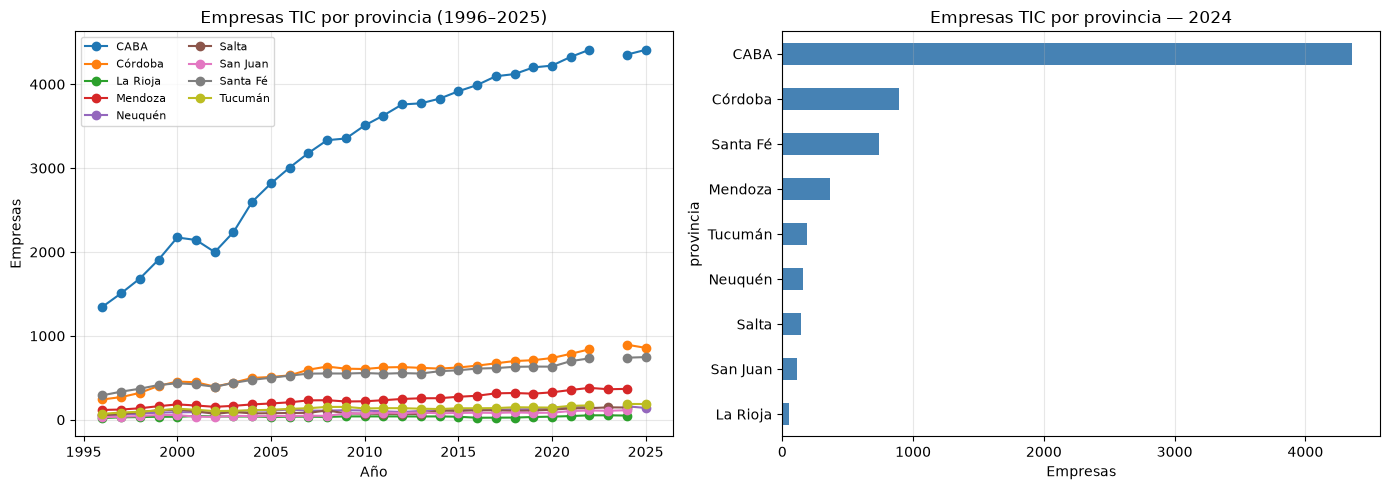

Top ramas TIC — La Rioja 2024:
Descripción
Actividades de informática      27.0
Telecomunicaciones y correos    23.0
Investigación y desarrollo       0.0


In [13]:
# Celda 7 — Exploratorio: TIC en La Rioja vs benchmark
import matplotlib.pyplot as plt
import pandas as pd
import src.funciones as fn

df = fn.cargar_empresas_benchmark(ramas_2d=["72", "73", "64"])

# --- Gráfico 1: evolución TIC por provincia ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Serie temporal
piv = (df.groupby(["anio", "provincia"])["empresas"]
         .sum().unstack("provincia"))
piv.plot(ax=axes[0], marker="o", linewidth=1.5)
axes[0].set_title("Empresas TIC por provincia (1996–2025)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Empresas")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, ncol=2)

# (b) Ranking 2024 (año común a todas)
r24 = (df[df["anio"] == 2024]
       .groupby("provincia")["empresas"].sum()
       .sort_values(ascending=True))
r24.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Empresas TIC por provincia — 2024")
axes[1].set_xlabel("Empresas")
axes[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()

# --- Gráfico 2: top ramas TIC en La Rioja (2024) ---
lr = df[(df["provincia"] == "La Rioja") & (df["anio"] == 2024)]
top = (lr.groupby("Descripción")["empresas"].sum()
         .sort_values(ascending=False))
print("Top ramas TIC — La Rioja 2024:")
print(top.to_string())

In [14]:
# Celda 9 — Probar indicadores IPC (NOA vs Nacional)
import importlib
import src.funciones as fn
import src.indicadores as ind
importlib.reload(fn); importlib.reload(ind)

ipc = fn.cargar_ipc_regional()
print("Tidy IPC:", ipc.shape)

# Interanual
ipc_ia = ind.ipc_variacion_interanual(ipc)
print("\nInteranual — últimos 3 meses NOA (Nivel general):")
m = (ipc_ia[(ipc_ia["region"] == "Región Noroeste") &
            (ipc_ia["categoria"] == "Nivel general")]
        .sort_values("fecha").tail(3))
print(m.to_string(index=False))

# Interanual — comparación NOA vs Nacional (últimos 12 meses)
comp = (ipc_ia[ipc_ia["categoria"] == "Nivel general"]
        .pivot_table(index="fecha", columns="region",
                     values="var_interanual")
        .tail(12))
print("\nInteranual Nivel general — últimas 12 fechas:")
print(comp.round(2).to_string())

# Acumulado anual
acum = ind.ipc_acumulado_anual(ipc)
print("\nAcumulado anual NOA (Nivel general) — últimas 3 fechas:")
m = (acum[(acum["region"] == "Región Noroeste") &
          (acum["categoria"] == "Nivel general")]
        .sort_values("fecha").tail(3))
print(m.to_string(index=False))

# Índice base 100
idx = ind.ipc_indice_base100(ipc, "2017-01-01")
print("\nÍndice base 100 (2017-01) — NOA Nivel general, últimas 3:")
m = (idx[(idx["region"] == "Región Noroeste") &
         (idx["categoria"] == "Nivel general")]
        .sort_values("fecha").tail(3))
print(m.to_string(index=False))

Tidy IPC: (14616, 4)

Interanual — últimos 3 meses NOA (Nivel general):
         region     categoria      fecha  var_interanual
Región Noroeste Nivel general 2026-06-01       33.800619
Región Noroeste Nivel general 2026-07-01       34.195311
Región Noroeste Nivel general 2026-08-01       33.932183

Interanual Nivel general — últimas 12 fechas:
region      Región Cuyo  Región GBA  Región Noreste  Región Noroeste  Región Pampeana  Región Patagonia  Total nacional
fecha                                                                                                                  
2025-09-01        29.94       32.63           28.17            31.71            30.96             35.25           31.73
2025-10-01        30.07       32.12           27.67            31.07            30.58             34.20           31.22
2025-11-01        30.96       31.99           28.42            31.58            30.84             32.90           31.35
2025-12-01        31.86       31.86           29.05  

In [15]:
# Celda 11 — Probar indicadores empresas (La Rioja + TIC)
import importlib
import src.funciones as fn
import src.indicadores as ind
importlib.reload(fn); importlib.reload(ind)

# --- La Rioja total (suma de secciones A-Z) ---
lr = fn.cargar_empresas_provincia("La Rioja")
tot = (lr[lr["Ramas"].str.match(r"^[A-Z]$", na=False)]
       .groupby("anio")["empresas"].sum()
       .reset_index())
tot_ia = ind.empresas_variacion_interanual(
    tot.assign(provincia="La Rioja", Ramas="TOTAL",
               Descripción="TOTAL")
)
print("La Rioja — total empresas y var. interanual (últ. 10 años):")
print(tot_ia.tail(10).round(2).to_string(index=False))

# --- Participación sectorial 2024 ---
part = ind.empresas_participacion_sectorial(lr, anio=2024, nivel="seccion")
print("\nParticipación por sección — La Rioja 2024:")
print(part[["Ramas", "Descripción", "empresas", "participacion"]]
      .round(2).to_string(index=False))

# --- Índice base 100 para TIC ---
tic = fn.cargar_empresas_benchmark(ramas_2d=["72", "73", "64"])
tic_agg = (tic.groupby(["provincia", "anio"])["empresas"].sum()
             .reset_index()
             .assign(Ramas="TIC", Descripción="TIC"))
tic_idx = ind.empresas_indice_base100(tic_agg, anio_base=2000)
piv = (tic_idx[tic_idx["anio"].between(2000, 2024)]
       .pivot_table(index="anio", columns="provincia",
                    values="indice"))
print("\nÍndice base 100 (2000) — TIC por provincia:")
print(piv.round(1).tail(8).to_string())

La Rioja — total empresas y var. interanual (últ. 10 años):
 anio  empresas provincia Ramas Descripción  var_ia
 2015    2816.0  La Rioja TOTAL       TOTAL    0.72
 2016    2861.0  La Rioja TOTAL       TOTAL    1.60
 2017    2858.0  La Rioja TOTAL       TOTAL   -0.10
 2018    2823.0  La Rioja TOTAL       TOTAL   -1.22
 2019    2683.0  La Rioja TOTAL       TOTAL   -4.96
 2020    2561.0  La Rioja TOTAL       TOTAL   -4.55
 2021    2604.0  La Rioja TOTAL       TOTAL    1.68
 2022    3017.0  La Rioja TOTAL       TOTAL   15.86
 2023    3388.0  La Rioja TOTAL       TOTAL   12.30
 2024    3082.0  La Rioja TOTAL       TOTAL   -9.03

Participación por sección — La Rioja 2024:
Ramas                                                    Descripción  empresas  participacion
    G                           COMERCIO AL POR MAYOR Y AL POR MENOR    1286.0          41.73
    K           SERVICIOS INMOBILIARIOS, EMPRESARIALES Y DE ALQUILER     305.0           9.90
    A                    AGRICULTURA, GANA

In [16]:
# Celda 11.bis — Chequear NaN 2023 TIC
import src.funciones as fn
tic = fn.cargar_empresas_benchmark(ramas_2d=["72", "73", "64"])

# ¿Qué pasa en 2023 por provincia?
print(tic[tic["anio"] == 2023]
      .groupby("provincia")["empresas"]
      .agg(["count", "sum", "size"])
      .to_string())

# ¿Y qué había en 2022 vs 2024?
for a in (2022, 2023, 2024):
    s = tic[tic["anio"] == a].groupby("provincia")["empresas"].sum()
    print(f"\n{a}:")
    print(s.to_string())

           count    sum  size
provincia                    
La Rioja       2   53.0     3
Mendoza        3  364.0     3
Salta          3  148.0     3
San Juan       3  107.0     3

2022:
provincia
CABA        4411.0
Córdoba      840.0
La Rioja      53.0
Mendoza      380.0
Neuquén      149.0
Salta        138.0
San Juan     111.0
Santa Fé     732.0
Tucumán      171.0

2023:
provincia
La Rioja     53.0
Mendoza     364.0
Salta       148.0
San Juan    107.0

2024:
provincia
CABA        4353.0
Córdoba      895.0
La Rioja      50.0
Mendoza      368.0
Neuquén      160.0
Salta        146.0
San Juan     114.0
Santa Fé     740.0
Tucumán      188.0


In [17]:
# Celda 11.ter — Diagnóstico CABA: columnas y años detectados
import pandas as pd
import src.funciones as fn

archivo, hoja = fn._archivo_y_hoja_real("CABA")
print("Archivo:", archivo.name)
print("Hoja:", hoja)

# 1) Primeras filas crudas
raw = pd.read_excel(archivo, sheet_name=hoja, header=None,
                    engine="openpyxl", nrows=8)
print("\n--- Primeras 8 filas crudas (primeras 12 columnas) ---")
print(raw.iloc[:, :12].to_string())

# 2) Detectar header igual que la función
mejor_fila, mejor_score = None, 0
for i in range(len(raw)):
    score = 0
    for v in raw.iloc[i].values:
        try:
            n = int(float(v))
            if 1990 <= n <= 2100:
                score += 1
        except (ValueError, TypeError):
            continue
    if score > mejor_score:
        mejor_score = score
        mejor_fila = i
print(f"\nHeader detectado en fila {mejor_fila} (score={mejor_score})")

# 3) Leer con ese header y ver columnas
df = pd.read_excel(archivo, sheet_name=hoja, header=mejor_fila,
                   engine="openpyxl")
cols = [str(c).strip() for c in df.columns]
print("\n--- Columnas detectadas ---")
print(cols)

# 4) ¿Aparece '2023'?
print("\n¿'2023' en columnas?:", "2023" in cols)
print("Columnas que contienen '202':",
      [c for c in cols if "202" in c])

Archivo: provinciales_serie_empresas3_2.xlsx
Hoja: CABA

--- Primeras 8 filas crudas (primeras 12 columnas) ---
                                                                                                                                  0            1       2       3       4       5       6       7       8       9       10      11
0                                                                                                                                NaN          NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
1                                                                                                    CIUDAD AUTÓNOMA DE BUENOS AIRES          NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
2  Empresas del sector privado. Según rama de actividad a 4 dígitos del CIIU rev. 3. Activas al cierre de cada año. Anual 1996-2024.          NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN 

In [18]:
# Celda 11.quater — Cobertura temporal del benchmark TIC
import importlib
import src.funciones as fn
import src.indicadores as ind
importlib.reload(fn); importlib.reload(ind)

tic = fn.cargar_empresas_benchmark(ramas_2d=["72", "73", "64"])

print("Último año común (todas las provincias):",
      ind.ultimo_anio_comun(tic))

print("\nAños faltantes por provincia:")
tabla = ind.anios_faltantes_por_provincia(tic, 1996, 2025)
print(tabla.to_string(index=False))

Último año común (todas las provincias): 2024

Años faltantes por provincia:
provincia anios_faltantes  n_faltantes
     CABA          [2023]            1
  Córdoba          [2023]            1
 La Rioja          [2025]            1
  Mendoza          [2025]            1
  Neuquén          [2023]            1
    Salta          [2025]            1
 San Juan          [2025]            1
 Santa Fé          [2023]            1
  Tucumán          [2023]            1


In [19]:
# Celda 12 — Panel resumen La Rioja
import importlib
import pandas as pd
import src.funciones as fn
import src.indicadores as ind
importlib.reload(fn); importlib.reload(ind)

# --- IPC NOA: último dato ---
ipc = fn.cargar_ipc_regional()
ipc_ia = ind.ipc_variacion_interanual(ipc)
ipc_ac = ind.ipc_acumulado_anual(ipc)

def _ult(df, col, region="Región Noroeste", cat="Nivel general"):
    m = (df[(df["region"] == region) & (df["categoria"] == cat)]
         .sort_values("fecha").iloc[-1])
    return m["fecha"].strftime("%Y-%m"), round(m[col], 2)

f_ia, v_ia = _ult(ipc_ia, "var_interanual")
f_ac, v_ac = _ult(ipc_ac, "acum_anual")

# --- Empresas La Rioja (total, sin doble conteo) ---
lr = fn.cargar_empresas_provincia("La Rioja")
lr_tot = ind.empresas_total_provincia(lr)

ult_lr = lr_tot.dropna(subset=["var_ia"]).sort_values("anio").iloc[-1]
ant_lr = lr_tot[lr_tot["anio"] == ult_lr["anio"] - 1].iloc[0]

# --- TIC La Rioja (2024, último año común) ---
tic = fn.cargar_empresas_benchmark(ramas_2d=["72", "73", "64"])
tic_lr = (tic[tic["provincia"] == "La Rioja"]
          .groupby("anio")["empresas"].sum())
tic_2024 = tic_lr.loc[2024]
tic_2023 = tic_lr.loc[2023]
tic_var = (tic_2024 / tic_2023 - 1) * 100

# --- Ranking TIC 2024 ---
tic_24 = (tic[tic["anio"] == 2024]
          .groupby("provincia")["empresas"].sum()
          .sort_values(ascending=False))
pos_lr = list(tic_24.index).index("La Rioja") + 1

print("=" * 60)
print("PANEL LA RIOJA — RESUMEN")
print("=" * 60)

print(f"\n[IPC NOA — Nivel general]")
print(f"  Interanual    ({f_ia}):     {v_ia:>7.2f} %")
print(f"  Acumulado año ({f_ac}):     {v_ac:>7.2f} %")

print(f"\n[Empresas totales La Rioja]")
print(f"  {int(ult_lr['anio'])}:      {int(ult_lr['empresas']):>7,} empresas")
print(f"  {int(ant_lr['anio'])}:      {int(ant_lr['empresas']):>7,} empresas")
print(f"  Variación interanual:        {ult_lr['var_ia']:>7.2f} %")

print(f"\n[Empresas TIC La Rioja]")
print(f"  2024:        {int(tic_2024):>7,} empresas")
print(f"  2023:        {int(tic_2023):>7,} empresas")
print(f"  Variación:                   {tic_var:>7.2f} %")
print(f"  Ranking TIC 2024:            {pos_lr}° de {len(tic_24)}")

print(f"\n[Ranking TIC 2024 — todas las provincias]")
for i, (prov, val) in enumerate(tic_24.items(), 1):
    marker = " ←" if prov == "La Rioja" else ""
    print(f"  {i}. {prov:<12}  {int(val):>5,}{marker}")

print("=" * 60)

PANEL LA RIOJA — RESUMEN

[IPC NOA — Nivel general]
  Interanual    (2026-08):       33.93 %
  Acumulado año (2026-08):       22.29 %

[Empresas totales La Rioja]
  2024:        3,082 empresas
  2023:        3,388 empresas
  Variación interanual:          -9.03 %

[Empresas TIC La Rioja]
  2024:             50 empresas
  2023:             53 empresas
  Variación:                     -5.66 %
  Ranking TIC 2024:            9° de 9

[Ranking TIC 2024 — todas las provincias]
  1. CABA          4,353
  2. Córdoba         895
  3. Santa Fé        740
  4. Mendoza         368
  5. Tucumán         188
  6. Neuquén         160
  7. Salta           146
  8. San Juan        114
  9. La Rioja         50 ←


In [20]:
# Celda 13 — Diagnóstico DGIP
# Fijar el CWD a la raíz del proyecto (donde está reports/, src/, data/)
import os
from pathlib import Path

# Si estamos en notebooks/, subimos un nivel
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

print("CWD ahora:", Path.cwd())
print("¿existe 'reports/bibliografia'?:", Path("reports/bibliografia").exists())
import pdfplumber
from pathlib import Path

base = Path("reports/bibliografia")

for pdf_path in sorted(base.glob("Informe*.pdf")):
    print("=" * 60)
    print(pdf_path.name)
    print("=" * 60)
    with pdfplumber.open(pdf_path) as pdf:
        print(f"Páginas: {len(pdf.pages)}")
        page = pdf.pages[0]
        # 1) ¿Hay texto extraíble?
        texto = page.extract_text() or ""
        print(f"Chars extraídos: {len(texto)}")
        print("\n--- Primeros 400 chars de texto ---")
        print(texto[:400])

        # 2) ¿Hay tablas detectables?
        tablas = page.extract_tables()
        print(f"\nTablas detectadas: {len(tablas)}")
        if tablas:
            t = tablas[0]
            print(f"Filas: {len(t)} | Cols: {len(t[0]) if t else 0}")
            print("\n--- Primeras 3 filas ---")
            for row in t[:3]:
                print(row)
    print()

CWD ahora: c:\Users\HP\Documents\Economy\economia_c
¿existe 'reports/bibliografia'?: True


In [21]:
# Celda 13.pre — Chequeo de entorno y rutas
import os, sys
from pathlib import Path

print("Python (kernel):", sys.executable)
print("CWD:", os.getcwd())

print("\n¿existe 'reports'?:", Path("reports").exists())
print("¿existe 'reports/bibliografia'?:", Path("reports/bibliografia").exists())

if Path("reports/bibliografia").exists():
    archivos = list(Path("reports/bibliografia").iterdir())
    print(f"\nArchivos en reports/bibliografia ({len(archivos)}):")
    for a in archivos:
        print("   ", a.name)

try:
    import pdfplumber
    print("\npdfplumber OK:", pdfplumber.__version__)
except Exception as e:
    print("\n[!] pdfplumber NO disponible en el kernel:", e)

Python (kernel): c:\Users\HP\Documents\Economy\economia_c\.venv\Scripts\python.exe
CWD: c:\Users\HP\Documents\Economy\economia_c

¿existe 'reports'?: True
¿existe 'reports/bibliografia'?: True

Archivos en reports/bibliografia (2):
    dgip_informe_tecnologico_2022-2023.pdf
    dgip_informe_tecnologico_2024-2025.pdf

pdfplumber OK: 0.11.10


In [22]:
# Celda 13.bis — Listar todo en reports/bibliografia
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

base = Path("reports/bibliografia")
print("CWD:", Path.cwd())
print("base:", base.resolve())
print("¿existe?:", base.exists())
print()

print("Contenido (recursivo):")
for p in sorted(base.rglob("*")):
    tipo = "DIR " if p.is_dir() else "FILE"
    size = "" if p.is_dir() else f"  ({p.stat().st_size/1024:.1f} KB)"
    print(f"  [{tipo}] {p.relative_to(base)}{size}")

CWD: c:\Users\HP\Documents\Economy\economia_c
base: C:\Users\HP\Documents\Economy\economia_c\reports\bibliografia
¿existe?: True

Contenido (recursivo):
  [FILE] dgip_informe_tecnologico_2022-2023.pdf  (45.9 KB)
  [FILE] dgip_informe_tecnologico_2024-2025.pdf  (46.0 KB)


In [23]:
# Celda 13 — Diagnóstico DGIP (nombres correctos)
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import pdfplumber

base = Path("reports/bibliografia")
pdfs = sorted(base.glob("dgip_*.pdf"))

for pdf_path in pdfs:
    print("=" * 60)
    print(pdf_path.name)
    print("=" * 60)
    with pdfplumber.open(pdf_path) as pdf:
        print(f"Páginas: {len(pdf.pages)}")
        page = pdf.pages[0]

        texto = page.extract_text() or ""
        print(f"Chars extraídos: {len(texto)}")
        if texto:
            print("\n--- Primeros 400 chars ---")
            print(texto[:400])

        tablas = page.extract_tables()
        print(f"\nTablas detectadas: {len(tablas)}")
        if tablas:
            t = tablas[0]
            print(f"Filas: {len(t)} | Cols: {len(t[0]) if t and t[0] else 0}")
            print("\n--- Primeras 3 filas ---")
            for row in t[:3]:
                print(row)
    print()

dgip_informe_tecnologico_2022-2023.pdf
Páginas: 1
Chars extraídos: 2313

--- Primeros 400 chars ---
COD ACTIVIDAD 2022 2023
CONTRIB. CONTRIB. IMPUESTO CONTRIB. CONTRIB. IMPUESTO
BASE DECLAR. BASE DECLAR. BASE DECLAR. BASE DECLAR.
CONVENIO LOCAL TOTAL CONVENIO LOCAL TOTAL
Servicios de consultores en informática y suministros de
620104 331 $ 61.087.897,24 236 $ 42.626.699,10 $ 3.229.280,05 359 $ 1.283.750.000,27 252 $ 376.557.811,77 $ 58.509.224,92
programas de informática
620300 Servicios de cons

Tablas detectadas: 1
Filas: 15 | Cols: 12

--- Primeras 3 filas ---
['COD', 'ACTIVIDAD', '2022', None, None, None, None, '2023', None, None, None, None]
[None, None, 'CONTRIB.\nCONVENIO', 'BASE DECLAR.', 'CONTRIB.\nLOCAL', 'BASE DECLAR.', 'IMPUESTO\nTOTAL', 'CONTRIB.\nCONVENIO', 'BASE DECLAR.', 'CONTRIB.\nLOCAL', 'BASE DECLAR.', 'IMPUESTO\nTOTAL']
['620104', 'Servicios de consultores en informática y suministros de\nprogramas de informática', '331', '$ 61.087.897,24', '236', '$ 42.626.699,10',

In [24]:
import inspect
import src.dgip as dg

print("=== dgip_variacion_interanual ===")
print(inspect.getsource(dg.dgip_variacion_interanual))
print("\n=== dgip_total_anual ===")
print(inspect.getsource(dg.dgip_total_anual))

=== dgip_variacion_interanual ===
def dgip_variacion_interanual(df: pd.DataFrame) -> pd.DataFrame:
    """
    Variación interanual (%) por actividad para cada métrica:
    contrib_conv, contrib_local, base_conv, base_local, impuesto_total.
    """
    df = df.sort_values(["cod", "anio"]).copy()
    for col in ["contrib_conv", "contrib_local",
                "base_conv", "base_local", "impuesto_total"]:
        df[f"var_ia_{col}"] = (
            df.groupby("cod")[col].pct_change() * 100
        )
    return df


=== dgip_total_anual ===
def dgip_total_anual(df: pd.DataFrame) -> pd.DataFrame:
    """
    Suma de todas las actividades por año (los 'totales' del informe,
    recalculados por nosotros).
    """
    return (df.groupby("anio")[["contrib_conv", "contrib_local",
                                 "base_conv", "base_local",
                                 "impuesto_total"]]
              .sum().reset_index())



In [25]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import importlib
import src.dgip as dg
importlib.reload(dg)

base = Path("reports/bibliografia")
pdfs = sorted(base.glob("dgip_*.pdf"))
print("PDFs:", [p.name for p in pdfs])

df = dg.cargar_dgip_tecnologico_multi(pdfs)
print(f"\nShape: {df.shape}")
print(f"Años: {sorted(df['anio'].unique())}")
print(f"Actividades únicas: {df['cod'].nunique()}")
print("\n--- Primeras filas ---")
print(df.head(10).to_string(index=False))

# --- Totales por año ---
print("\n--- Totales por año ---")
print(dg.dgip_total_anual(df).to_string(index=False))

# --- Variaciones interanuales ---
df_ia = dg.dgip_variacion_interanual(df)
print("\n--- Variación IA impuesto total (por actividad, último año) ---")
u = (df_ia[df_ia["anio"] == df_ia["anio"].max()]
     [["cod", "actividad", "anio", "impuesto_total",
       "var_ia_impuesto_total",        # ← CORREGIDO
       "var_ia_contrib_conv"]]
     .sort_values("impuesto_total", ascending=False))
print(u.round(2).to_string(index=False))

# --- Participación ---
print("\n--- Participación en impuesto total por año ---")
p = dg.dgip_participacion(df)
print(p.pivot_table(index="cod", columns="anio",
                    values="participacion").round(2).to_string())

PDFs: ['dgip_informe_tecnologico_2022-2023.pdf', 'dgip_informe_tecnologico_2024-2025.pdf']

Shape: (48, 8)
Años: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Actividades únicas: 12

--- Primeras filas ---
   cod                                                                         actividad  anio  contrib_conv    base_conv  contrib_local   base_local  impuesto_total
620104 Servicios de consultores en informática y suministros de programas de informática  2022           331 6.108790e+07            236 4.262670e+07      3229280.05
620104 Servicios de consultores en informática y suministros de programas de informática  2023           359 1.283750e+09            252 3.765578e+08     58509224.92
620104 Servicios de consultores en informática y suministros de programas de informática  2024           349 3.522641e+09            159 1.328525e+09    174955127.69
620104 Servicios de consultores en informática y suministros de programas de informática  2025           384 1.

In [26]:
# Celda 14.bis — Variaciones y participación (corregida)
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import importlib
import src.dgip as dg
importlib.reload(dg)

base = Path("reports/bibliografia")
df = dg.cargar_dgip_tecnologico_multi(sorted(base.glob("dgip_*.pdf")))

# --- 1) Variación IA impuesto total, sólo último año ---
df_ia = dg.dgip_variacion_interanual(df)
u = df_ia[df_ia["anio"] == df_ia["anio"].max()].copy()
u["act_corta"] = u["actividad"].str.slice(0, 40)

print("--- Variación IA impuesto total (último año) ---")
print(u[["cod", "act_corta", "anio",
         "impuesto_total", "var_ia_impuesto_total",
         "var_ia_contrib_conv", "var_ia_contrib_local"]]
      .round(2)
      .to_string(index=False))

# --- 2) Impuesto total por actividad y año ---
print("\n--- Impuesto total por actividad y año ---")
piv = df.pivot_table(index="cod", columns="anio",
                     values="impuesto_total")
piv["act_corta"] = (df.drop_duplicates("cod")
                      .set_index("cod")["actividad"]
                      .str.slice(0, 35))
print(piv[["act_corta"] + [c for c in piv.columns if c != "act_corta"]]
      .round(0)
      .to_string())

# --- 3) Participación en impuesto total por año ---
print("\n--- Participación (%) en impuesto total ---")
p = dg.dgip_participacion(df)
piv_p = p.pivot_table(index="cod", columns="anio",
                      values="participacion")
print(piv_p.round(2).to_string())

# --- 4) Contribuyentes y base por año ---
print("\n--- Contribuyentes y base por año ---")
print(dg.dgip_total_anual(df).to_string(index=False))

--- Variación IA impuesto total (último año) ---
   cod                                act_corta  anio  impuesto_total  var_ia_impuesto_total  var_ia_contrib_conv  var_ia_contrib_local
620104 Servicios de consultores en informática   2025    689118363.06                 293.88                10.03                 -9.43
620300 Servicios de consultores en tecnología d  2025      6558175.98                  23.07                 8.15                 18.75
620900          Servicios de informática n.c.p.  2025    922578555.58                  86.15                19.73                  0.68
711002    Servicios geológicos y de prospección  2025      8048052.36                 -11.17                -3.57                  0.00
721010 Investigación y desarrollo experimental   2025     13220757.83                  78.20                12.90                  0.00
721020 Investigación y desarrollo experimental   2025     43489072.68                  49.31               -20.00                 -6.90

In [27]:
# Celda 16 — DGIP: nominal, constante 2022, constante 2024, índices
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import importlib
import src.funciones as fn
import src.dgip as dg
importlib.reload(fn); importlib.reload(dg)

base = Path("reports/bibliografia")
df_dgip = dg.cargar_dgip_tecnologico_multi(sorted(base.glob("dgip_*.pdf")))
ipc = fn.cargar_ipc_regional()

# --- 1) Nominal ---
nom = dg.dgip_total_anual(df_dgip)

# --- 2) Pesos constantes de 2022 ---
def_22 = dg.dgip_deflactar(df_dgip, ipc, anio_base=2022)
const_22 = (def_22.groupby("anio")["impuesto_total_const"]
                   .sum().reset_index()
                   .rename(columns={"impuesto_total_const": "impuesto_const_2022"}))

# --- 3) Pesos constantes de 2024 ---
def_24 = dg.dgip_deflactar(df_dgip, ipc, anio_base=2024)
const_24 = (def_24.groupby("anio")["impuesto_total_const"]
                   .sum().reset_index()
                   .rename(columns={"impuesto_total_const": "impuesto_const_2024"}))

# --- 4) Índices base 100 ---
idx_22 = dg.dgip_indice(df_dgip, anio_base=2022)
idx_24 = dg.dgip_indice(df_dgip, anio_base=2024)

# --- Combinar todo ---
tabla = (nom[["anio", "impuesto_total", "contrib_conv", "contrib_local"]]
         .merge(const_22, on="anio")
         .merge(const_24, on="anio")
         .merge(idx_22[["anio", "impuesto_idx"]]
                .rename(columns={"impuesto_idx": "idx_2022"}),
                on="anio")
         .merge(idx_24[["anio", "impuesto_idx"]]
                .rename(columns={"impuesto_idx": "idx_2024"}),
                on="anio"))

# Variación real año a año (usando const_2022)
tabla["var_real_ia"] = tabla["impuesto_const_2022"].pct_change() * 100

print("=" * 90)
print("DGIP TECNOLÓGICO LA RIOJA — NOMINAL vs CONSTANTE vs ÍNDICES")
print("=" * 90)
print(tabla.round(2).to_string(index=False))

print("\n--- Lectura ---")
print(f"Base 2022 = 100 → 2025 vale {tabla.iloc[-1]['idx_2022']:.0f}")
print(f"Base 2024 = 100 → 2025 vale {tabla.iloc[-1]['idx_2024']:.0f}")

DGIP TECNOLÓGICO LA RIOJA — NOMINAL vs CONSTANTE vs ÍNDICES
 anio  impuesto_total  contrib_conv  contrib_local  impuesto_const_2022  impuesto_const_2024  idx_2022  idx_2024  var_real_ia
 2022    5.898752e+07          1752           1138          58987520.71         4.320393e+08    100.00      6.97          NaN
 2023    2.430125e+08          1911           1060         103749434.00         7.598868e+08    411.97     28.72        75.88
 2024    8.461294e+08          1947            844         115524375.21         8.461294e+08   1434.42    100.00        11.35
 2025    1.940909e+09          2075            840         186631041.87         1.366932e+09   3290.37    229.39        61.55

--- Lectura ---
Base 2022 = 100 → 2025 vale 3290
Base 2024 = 100 → 2025 vale 229


In [28]:
# Celda 16.bis — DGIP índices nominales vs reales
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import importlib
import src.funciones as fn
import src.dgip as dg
importlib.reload(fn); importlib.reload(dg)

base = Path("reports/bibliografia")
df_dgip = dg.cargar_dgip_tecnologico_multi(sorted(base.glob("dgip_*.pdf")))
ipc = fn.cargar_ipc_regional()
nom = dg.dgip_total_anual(df_dgip)

idx_22_nom  = dg.dgip_indice(df_dgip, anio_base=2022, real=False)
idx_22_real = dg.dgip_indice(df_dgip, anio_base=2022, df_ipc=ipc, real=True)
idx_24_real = dg.dgip_indice(df_dgip, anio_base=2024, df_ipc=ipc, real=True)

tabla = (nom[["anio", "impuesto_total", "contrib_conv", "contrib_local"]]
         .merge(idx_22_nom[["anio", "impuesto_idx"]]
                .rename(columns={"impuesto_idx": "idx_nom_2022"}), on="anio")
         .merge(idx_22_real[["anio", "impuesto_idx"]]
                .rename(columns={"impuesto_idx": "idx_real_2022"}), on="anio")
         .merge(idx_24_real[["anio", "impuesto_idx"]]
                .rename(columns={"impuesto_idx": "idx_real_2024"}), on="anio"))

print(tabla.round(2).to_string(index=False))

 anio  impuesto_total  contrib_conv  contrib_local  idx_nom_2022  idx_real_2022  idx_real_2024
 2022    5.898752e+07          1752           1138        100.00         100.00          51.06
 2023    2.430125e+08          1911           1060        411.97         175.88          89.81
 2024    8.461294e+08          1947            844       1434.42         195.85         100.00
 2025    1.940909e+09          2075            840       3290.37         316.39         161.55


In [29]:
# Celda 17 — Inventario de data/raw
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import pandas as pd

raw = Path("data/raw")
print(f"Archivos en {raw.resolve()}:")
for f in sorted(raw.iterdir()):
    if f.is_file():
        size_kb = f.stat().st_size / 1024
        print(f"  {f.name:<55} {size_kb:>8.1f} KB")
    else:
        print(f"  [DIR] {f.name}")

Archivos en C:\Users\HP\Documents\Economy\economia_c\data\raw:
  03.a_expo_prov_it_sector_datos.csv                         134.4 KB
  03.b_expo_prov_it_destino_datos.csv                       1416.0 KB
  actividad_ied.xlsx                                        5105.7 KB
  cuadros_tic_05_25.xls                                      106.5 KB
  equipos-sistemas-nacionales.csv                            114.0 KB
  Internet Accesos Tecnologias Provincias.xlsx                67.8 KB
  inversion_en_id_sector_empresario.csv                       12.8 KB
  inversion_en_id_x_tipo_financiamiento.csv                   32.5 KB
  investigadores_por_nivel_educativo.csv                      31.7 KB
  nacional_serie_empleo_trimestral_7.xlsx                   3315.2 KB
  nacional_serie_empresas_2.xlsx                             424.8 KB
  personal_en_id.csv                                           6.4 KB
  provinciales_serie_empleo_anual_3.xlsx                     643.8 KB
  provinciales_serie_empleo

In [30]:
import os
from pathlib import Path
import pandas as pd
import numpy as np

# Setup obligatorio
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
print("CWD:", Path.cwd())

RAW = Path("data/raw")
assert RAW.exists(), f"No existe {RAW.resolve()}"

# --- Archivos Prioridad 1 ---
PRIO1 = {
    "empleo_priv_formal_prov":       "SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx",
    "salario_priv_formal_prov":      "SerieWeb_SALARIO_PRIVADO_FORMAL_provincias.xlsx",
    "empleo_anual_3dig":             "provinciales_serie_empleo_anual_3.xlsx",
    "empleo_trim_2dig":              "provinciales_serie_empleo_trimestral_2dig_6.xlsx",
    "empleo_trim_4dig":              "provinciales_serie_empleo_trimestral_4dig_7.xlsx",
    "remun_anual_3dig":              "provinciales_serie_remuneraciones_anual_3.xlsx",
    "remun_mensual_2dig":            "provinciales_serie_remuneraciones_mensual_2dig_8.xlsx",
    "remun_mensual_4dig":            "provinciales_serie_remuneraciones_mensual_4dig_7.xlsx",
    "empleo_nacional_trim":          "nacional_serie_empleo_trimestral_7.xlsx",
}

# Chequeo existencia
faltan = [f for f in PRIO1.values() if not (RAW / f).exists()]
if faltan:
    print("⚠️ Faltan:", faltan)
else:
    print("✅ Los 9 archivos de Prioridad 1 están presentes.")

CWD: c:\Users\HP\Documents\Economy\economia_c
✅ Los 9 archivos de Prioridad 1 están presentes.


In [31]:
def espiar_xlsx(path, n_head=6, max_cols=15):
    """Reporta hojas, dimensiones y preview crudo de cada hoja."""
    path = Path(path)
    print("=" * 90)
    print(f"📄 {path.name}")
    print("=" * 90)
    try:
        xl = pd.ExcelFile(path)
    except Exception as e:
        print("  ❌ No se pudo abrir:", e)
        return
    print(f"  Hojas ({len(xl.sheet_names)}): {xl.sheet_names}\n")
    for sh in xl.sheet_names:
        try:
            df = xl.parse(sh, header=None, nrows=12)
        except Exception as e:
            print(f"  [{sh}] error: {e}"); continue
        # forma real (sin header)
        full = xl.parse(sh, header=None)
        print(f"  ── Hoja: '{sh}'  → shape crudo {full.shape}")
        with pd.option_context("display.max_columns", max_cols,
                               "display.width", 200,
                               "display.max_colwidth", 22):
            print(df.iloc[:n_head, :max_cols].to_string())
        print()

for f in PRIO1.values():
    if (RAW / f).exists():
        espiar_xlsx(RAW / f)

📄 SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx
  Hojas (3): ['serie_original', 'serie_desestacionalizada', 'variaciones %']

  ── Hoja: 'serie_original'  → shape crudo (28, 211)
                                 0                    1                    2                    3                    4                    5                    6                    7                    8                    9                    10                   11                   12                   13                   14
0  -en miles de puestos de trabajo-  2009-01-01 00:00:00  2009-02-01 00:00:00  2009-03-01 00:00:00  2009-04-01 00:00:00  2009-05-01 00:00:00  2009-06-01 00:00:00  2009-07-01 00:00:00  2009-08-01 00:00:00  2009-09-01 00:00:00  2009-10-01 00:00:00  2009-11-01 00:00:00  2009-12-01 00:00:00  2010-01-01 00:00:00  2010-02-01 00:00:00
1                            Bs. As              1787.64             1769.223             1745.913             1729.917             1723.218             1724.90

In [32]:
def detectar_header_y_esquema(path, sheet=0, max_busqueda=10):
    """Busca la fila de header (la primera con >=3 strings no nulos) y devuelve dtypes."""
    raw = pd.read_excel(path, sheet_name=sheet, header=None, nrows=max_busqueda + 5)
    header_row = 0
    for i in range(min(max_busqueda, len(raw))):
        fila = raw.iloc[i]
        n_str = fila.apply(lambda v: isinstance(v, str) and len(v.strip()) > 0).sum()
        if n_str >= 3:
            header_row = i
            break
    df = pd.read_excel(path, sheet_name=sheet, header=header_row)
    df = df.dropna(how="all").dropna(axis=1, how="all")
    print(f"📄 {Path(path).name} | hoja='{sheet}' | header_row={header_row}")
    print(f"   shape: {df.shape}")
    print(f"   columnas: {list(df.columns)[:20]}")
    print(f"   dtypes:\n{df.dtypes.value_counts().to_string()}")
    print(f"   head:\n{df.head(4).to_string(max_cols=12)}\n")
    return df, header_row

# Probar con los 4 archivos "provinciales_serie_*" que probablemente tengan títulos
for f in ["provinciales_serie_empleo_anual_3.xlsx",
          "provinciales_serie_empleo_trimestral_2dig_6.xlsx",
          "provinciales_serie_remuneraciones_anual_3.xlsx",
          "provinciales_serie_remuneraciones_mensual_2dig_8.xlsx"]:
    if (RAW / f).exists():
        try:
            df, hr = detectar_header_y_esquema(RAW / f)
        except Exception as e:
            print(f"❌ {f}: {e}\n")

📄 provinciales_serie_empleo_anual_3.xlsx | hoja='0' | header_row=0
   shape: (0, 0)
   columnas: []
   dtypes:
Series([], )
   head:
Empty DataFrame
Columns: []
Index: []

📄 provinciales_serie_empleo_trimestral_2dig_6.xlsx | hoja='0' | header_row=0
   shape: (0, 0)
   columnas: []
   dtypes:
Series([], )
   head:
Empty DataFrame
Columns: []
Index: []

📄 provinciales_serie_remuneraciones_anual_3.xlsx | hoja='0' | header_row=0
   shape: (0, 0)
   columnas: []
   dtypes:
Series([], )
   head:
Empty DataFrame
Columns: []
Index: []

📄 provinciales_serie_remuneraciones_mensual_2dig_8.xlsx | hoja='0' | header_row=0
   shape: (0, 0)
   columnas: []
   dtypes:
Series([], )
   head:
Empty DataFrame
Columns: []
Index: []



In [33]:
import importlib, sys
from pathlib import Path
import os
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import src.empleo as emp
importlib.reload(emp)

# --- 1) Re-chequear que empleo sigue OK (regresión) ---
lr_sec = emp.cargar_empleo_sector_provincia("La Rioja", solo_nivel="seccion")
ult = lr_sec["fecha"].max()
total_sec = lr_sec.query("fecha == @ult")["puestos"].sum()
print(f"✓ Regresión empleo — La Rioja secciones suman: {total_sec:,.0f} (esperado 28.442)")
assert abs(total_sec - 28442) < 1, "regresión: el parser de empleo cambió"

# --- 2) Salario TIC núcleo ---
print("\n=== Salario TIC núcleo LR ===")
sal_tic = emp.salario_tic_la_rioja("La Rioja", ampliado=False, frecuencia="mensual")
print("Shape:", sal_tic.shape)
if not sal_tic.empty:
    print("Ramas:", sal_tic["rama"].unique().tolist())
    print("Rango fechas:", sal_tic["fecha"].min().date(), "→", sal_tic["fecha"].max().date())
    print("\nÚltimos 8:")
    print(sal_tic.sort_values("fecha").tail(8).to_string(index=False))
else:
    print("⚠️  DataFrame vacío")

# --- 3) Salario general LR ---
print("\n=== Salario general LR (hoja Total) ===")
sal_gen = emp.cargar_remuneracion_total_provincias(frecuencia="mensual")
lr_gen = sal_gen.query("provincia == 'La Rioja'")
print("Shape:", lr_gen.shape)
if not lr_gen.empty:
    print("Rango fechas:", lr_gen["fecha"].min().date(), "→", lr_gen["fecha"].max().date())
    print(lr_gen.sort_values("fecha").tail(4).to_string(index=False))

# --- 4) Prima salarial TIC ---
print("\n=== Prima salarial TIC núcleo ===")
prima = emp.prima_salarial_tic("La Rioja", ampliado=False, frecuencia="mensual")
print("Shape:", prima.shape)
if not prima.empty:
    print(prima.tail(8).to_string(index=False))
else:
    print("⚠️  DataFrame vacío (posible merge fallido)")

# --- 5) Prima salarial TIC ampliado ---
print("\n=== Prima salarial TIC ampliado (incluye 73, 74) ===")
prima_amp = emp.prima_salarial_tic("La Rioja", ampliado=True, frecuencia="mensual")
print("Shape:", prima_amp.shape)
if not prima_amp.empty:
    print(prima_amp.tail(4).to_string(index=False))

✓ Regresión empleo — La Rioja secciones suman: 28,442 (esperado 28.442)

=== Salario TIC núcleo LR ===
Shape: (714, 6)
Ramas: ['Telecomunicaciones y correos', 'Actividades de informática']
Rango fechas: 1995-01-01 → 2026-03-01

Últimos 8:
provincia codigo                         rama      fecha  remuneracion_prom    nivel
 La Rioja     72   Actividades de informática 2025-12-01       3.434104e+06 division
 La Rioja     64 Telecomunicaciones y correos 2025-12-01       3.213338e+06 division
 La Rioja     64 Telecomunicaciones y correos 2026-01-01       2.718008e+06 division
 La Rioja     72   Actividades de informática 2026-01-01       2.089657e+06 division
 La Rioja     64 Telecomunicaciones y correos 2026-02-01       2.414649e+06 division
 La Rioja     72   Actividades de informática 2026-02-01       2.351598e+06 division
 La Rioja     64 Telecomunicaciones y correos 2026-03-01       2.968612e+06 division
 La Rioja     72   Actividades de informática 2026-03-01       2.504647e+06 divis

In [34]:
import importlib, sys
from pathlib import Path
import os
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import src.empleo as emp
importlib.reload(emp)

# Fechas normalizadas
sal_tic = emp.salario_tic_la_rioja("La Rioja", ampliado=False, frecuencia="mensual")
print("Día del mes:", sorted(sal_tic["fecha"].dt.day.unique()), "(esperado [1])")

# Regresión empleo
lr_sec = emp.cargar_empleo_sector_provincia("La Rioja", solo_nivel="seccion")
print(f"Empleo LR total: {lr_sec.query('fecha == @lr_sec[\"fecha\"].max()')['puestos'].sum():,.0f}")

# Prima
prima = emp.prima_salarial_tic("La Rioja", ampliado=False)
print(f"Prima TIC núcleo (últ. 12m): {prima.tail(12)['prima'].mean():.2f}×")
print(prima.tail(4).to_string(index=False))

Día del mes: [np.int32(1)] (esperado [1])
Empleo LR total: 28,442
Prima TIC núcleo (últ. 12m): 1.85×
     fecha  salario_tic  salario_general    prima
2025-12-01 3.323721e+06       1308234.91 2.540615
2026-01-01 2.403832e+06       1411095.64 1.703522
2026-02-01 2.383123e+06       1223365.51 1.948006
2026-03-01 2.736630e+06       1308234.91 2.091849


In [35]:
import json
from pathlib import Path
nb = json.loads(Path("notebooks/00_diagnostico.ipynb").read_text(encoding="utf-8"))
code_cells = [i for i, c in enumerate(nb["cells"]) if c["cell_type"] == "code"]
print(f"Celdas de código: {len(code_cells)}")
print(f"Índices: {code_cells}")

Celdas de código: 30
Índices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


In [36]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import inspect
import src.funciones as fn

print("=== Firma ===")
print(inspect.signature(fn.cargar_empresas_provincia))

print("\n=== Estructura SIPA La Rioja ===")
df = fn.cargar_empresas_provincia("La Rioja")
print("Shape:", df.shape)
print("Columnas:", df.columns.tolist())
print("\nHead:")
print(df.head(8).to_string())

print("\nÚltimo año — top 15 ramas:")
ult = df["anio"].max()
print(f"Último año: {ult}")
print(df[df["anio"] == ult].sort_values(df.columns[-1], ascending=False).head(15).to_string())

=== Firma ===
(provincia: str, fila_header: int | None = None) -> pandas.DataFrame

=== Estructura SIPA La Rioja ===
Shape: (2030, 5)
Columnas: ['provincia', 'Ramas', 'Descripción', 'anio', 'empresas']

Head:
  provincia Ramas                                    Descripción  anio  empresas
0  La Rioja     A    AGRICULTURA, GANADERIA, CAZA Y SILVICULTURA  1996     294.0
1  La Rioja     1                        Agricultura y ganaderia  1996       NaN
2  La Rioja     2             Silvicultura, extracción de madera  1996       NaN
3  La Rioja     B                      PESCA Y SERVICIOS CONEXOS  1996       NaN
4  La Rioja     5  Pesca y actividades relacionadas con la pesca  1996       NaN
5  La Rioja     C            EXPLOTACION  DE  MINAS  Y  CANTERAS  1996      12.0
6  La Rioja    11     Extraccion de petroleo crudo y gas natural  1996       NaN
7  La Rioja    13            Extraccion de minerales metaliferos  1996       NaN

Último año — top 15 ramas:
Último año: 2024
     provincia Ra

In [37]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.empleo as emp
importlib.reload(emp)

# --- 1) ¿Existen los códigos TIC en SIPA? ---
print("=== Divisiones SIPA disponibles (chequeo TIC) ===")
divs = emp.divisiones_disponibles_sipa("La Rioja")
tic = divs[divs["codigo"].isin(["64", "72", "73", "74"])]
print(tic.to_string(index=False))

# --- 2) Empresas TIC por año ---
print("\n=== Empresas TIC núcleo (64, 72) — SIPA ===")
empr_tic = emp.empresas_tic_sipa("La Rioja", ampliado=False)
print(empr_tic[["codigo", "Descripción", "anio", "empresas"]].to_string(index=False))

# --- 3) Puestos TIC / empresa TIC ---
print("\n=== Puestos TIC por empresa (núcleo) ===")
ppe = emp.empleo_por_empresa_tic("La Rioja", ampliado=False)
print(f"Shape: {ppe.shape}")
if not ppe.empty:
    print(ppe.to_string(index=False))

# --- 4) Ratio TIC vs promedio provincial ---
print("\n=== Tamaño medio TIC vs promedio provincial ===")
ratio = emp.ratio_tamano_tic_vs_promedio("La Rioja", ampliado=False)
print(f"Shape: {ratio.shape}")
if not ratio.empty:
    print(ratio.tail(8).to_string(index=False))

=== Divisiones SIPA disponibles (chequeo TIC) ===
codigo                                                 Descripción
    64                                Telecomunicaciones y correos
    72                                  Actividades de informática
    73                                  Investigación y desarrollo
    74 Servicios jurídicos, contables y otros servicios a empresas

=== Empresas TIC núcleo (64, 72) — SIPA ===
codigo                  Descripción  anio  empresas
    64 Telecomunicaciones y correos  1996      15.0
    64 Telecomunicaciones y correos  1997      21.0
    64 Telecomunicaciones y correos  1998      25.0
    64 Telecomunicaciones y correos  1999      28.0
    64 Telecomunicaciones y correos  2000      27.0
    64 Telecomunicaciones y correos  2001      36.0
    64 Telecomunicaciones y correos  2002      33.0
    64 Telecomunicaciones y correos  2003      32.0
    64 Telecomunicaciones y correos  2004      28.0
    64 Telecomunicaciones y correos  2005      24.

In [38]:
import src.empleo as emp

sipa = emp.cargar_empresas_sipa("La Rioja")
sipa_sec = sipa[sipa["codigo"].str.isalpha()]

print("Secciones detectadas:", sorted(sipa_sec["codigo"].unique()))
print(f"\nTotal secciones encontradas: {len(sipa_sec['codigo'].unique())}")

print("\nEmpresas 2024 por sección:")
print(sipa_sec[sipa_sec["anio"] == 2024].to_string())

print("\nSuma empresas 2024 (secciones):",
      sipa_sec[sipa_sec["anio"] == 2024]["empresas"].sum())

Secciones detectadas: ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'M', 'N', 'O']

Total secciones encontradas: 13

Empresas 2024 por sección:
     provincia codigo                                                     Descripción  anio  empresas
971   La Rioja      A                     AGRICULTURA, GANADERIA, CAZA Y SILVICULTURA  2024     241.0
997   La Rioja      C                             EXPLOTACION  DE  MINAS  Y  CANTERAS  2024       8.0
1026  La Rioja      D                                         INDUSTRIA MANUFACTURERA  2024     232.0
1055  La Rioja      E                                        ELECTRICIDAD, GAS Y AGUA  2024      13.0
1084  La Rioja      F                                                    CONSTRUCCION  2024     139.0
1113  La Rioja      G                            COMERCIO AL POR MAYOR Y AL POR MENOR  2024    1286.0
1142  La Rioja      H                                       HOTELERIA Y RESTAURANTES   2024     200.0
1171  La Rioja      I  SERVICIOS DE

In [39]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.empleo as emp
importlib.reload(emp)

ratio = emp.ratio_tamano_tic_vs_promedio("La Rioja", ampliado=False)
print(ratio.tail(8).to_string(index=False))

# Chequeo manual 2024
print("\n--- Chequeo manual 2024 ---")
sipa = emp.cargar_empresas_sipa("La Rioja")
empr_total = sipa[sipa["codigo"].str.isalpha() & (sipa["anio"] == 2024)]["empresas"].sum()
print(f"Empresas 2024 (secciones): {empr_total:.0f}")

emp_sec = emp.cargar_empleo_sector_provincia("La Rioja", solo_nivel="seccion")
emp_2024 = emp_sec[emp_sec["fecha"].dt.year == 2024]
print(f"Puestos 2024 (Q1..Q4): {sorted(emp_2024['puestos'].unique())}")
print(f"Promedio 2024: {emp_2024['puestos'].mean():.0f}")
print(f"Tamaño medio = {emp_2024['puestos'].mean() / empr_total:.2f}")

 anio  puestos_tic  empresas_tic  tamano_tic  tamano_promedio  ratio_tic_vs_promedio provincia
 2017   282.500000          25.0   11.300000         0.900219              12.552496  La Rioja
 2018   297.750000          26.0   11.451923         0.852312              13.436303  La Rioja
 2019   287.833333          33.0    8.722222         0.879017               9.922695  La Rioja
 2020   275.500000          37.0    7.445946         0.873705               8.522269  La Rioja
 2021   285.500000          44.0    6.488636         0.878611               7.385105  La Rioja
 2022   284.250000          53.0    5.363208         0.838645               6.395086  La Rioja
 2023   290.500000          53.0    5.481132         0.806807               6.793611  La Rioja
 2024   268.000000          50.0    5.360000         0.803986               6.666783  La Rioja

--- Chequeo manual 2024 ---
Empresas 2024 (secciones): 3082
Puestos 2024 (Q1..Q4): [np.float64(89.0), np.float64(97.0), np.float64(130.0), np.fl

In [40]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.empleo as emp
importlib.reload(emp)

ratio = emp.ratio_tamano_tic_vs_promedio("La Rioja", ampliado=False)
print("=== Tamaño medio TIC vs provincial ===")
print(ratio.tail(8).to_string(index=False))

# Chequeo manual 2024
print("\n--- Chequeo 2024 ---")
emp_sec = emp.cargar_empleo_sector_provincia("La Rioja", solo_nivel="seccion")
por_trim = emp_sec.groupby("fecha", as_index=False)["puestos"].sum()
por_trim["anio"] = por_trim["fecha"].dt.year
tot_2024 = por_trim[por_trim["anio"] == 2024]["puestos"]
print(f"Totales por trimestre 2024: {tot_2024.tolist()}")
print(f"Promedio 2024: {tot_2024.mean():.0f}")
print(f"Tamaño medio esperado: {tot_2024.mean() / 3082:.2f}")
print(f"Ratio esperado: {5.36 / (tot_2024.mean() / 3082):.3f}")

=== Tamaño medio TIC vs provincial ===
 anio  puestos_tic  empresas_tic  tamano_tic  tamano_promedio  ratio_tic_vs_promedio provincia
 2017   282.500000          25.0   11.300000        11.702852               0.965577  La Rioja
 2018   297.750000          26.0   11.451923        11.080057               1.033562  La Rioja
 2019   287.833333          33.0    8.722222        11.427227               0.763284  La Rioja
 2020   275.500000          37.0    7.445946        11.358161               0.655559  La Rioja
 2021   285.500000          44.0    6.488636        11.421947               0.568085  La Rioja
 2022   284.250000          53.0    5.363208        10.902386               0.491930  La Rioja
 2023   290.500000          53.0    5.481132        10.488489               0.522585  La Rioja
 2024   268.000000          50.0    5.360000        10.451817               0.512829  La Rioja

--- Chequeo 2024 ---
Totales por trimestre 2024: [36982.0, 32872.0, 29584.0, 29412.0]
Promedio 2024: 3221

In [41]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.empleo as emp
importlib.reload(emp)

# Serie completa por sección CIIU (trimestral 1996-2025)
df_sec = emp.cargar_empleo_sector_provincia("La Rioja", solo_nivel="seccion")
print(f"Shape: {df_sec.shape}")
print(f"Secciones: {sorted(df_sec['codigo'].unique())}")
print(f"Rango: {df_sec['fecha'].min().date()} → {df_sec['fecha'].max().date()}")

# Cobertura por año: ¿hay datos desde 1996?
cobertura = (df_sec.assign(anio=df_sec["fecha"].dt.year)
             .groupby("anio")
             .agg(n_secciones=("codigo", "nunique"),
                  n_trimestres=("fecha", "nunique")))
print("\nCobertura por año:")
print(cobertura.to_string())

# Snapshot 2003, 2015, 2019, 2025
for anio in [2003, 2015, 2019, 2025]:
    snap = (df_sec[df_sec["fecha"].dt.year == anio]
            .groupby("codigo")["puestos"].mean()
            .sort_values(ascending=False))
    print(f"\n=== Top 6 secciones {anio} ===")
    print(snap.head(6).to_string())

Shape: (1548, 6)
Secciones: ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'M', 'N', 'O']
Rango: 1996-03-31 → 2025-12-31

Cobertura por año:
      n_secciones  n_trimestres
anio                           
1996           13             4
1997           13             4
1998           13             4
1999           13             4
2000           13             4
2001           13             4
2002           12             4
2003           12             4
2004           13             4
2005           12             4
2006           13             4
2007           13             4
2008           13             4
2009           13             4
2010           13             4
2011           13             4
2012           13             4
2013           13             4
2014           13             4
2015           13             4
2016           13             4
2017           13             4
2018           13             4
2019           13             4
2020           13      

In [44]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.sectorial as sec
importlib.reload(sec)

# --- 1) Serie anual por sección ---
df = sec.serie_anual_por_seccion("La Rioja")
print(f"Shape: {df.shape}")
print(f"Sectores: {sorted(df['codigo'].unique())}")
print(f"Rango: {df['anio'].min()} → {df['anio'].max()}")

# --- 2) Snapshot 2025 ---
print("\n=== Empleo 2025 por sector ===")
snap = (df[df["anio"] == 2025]
        .sort_values("puestos", ascending=False)
        [["codigo", "sector", "puestos", "empresas", "salario_prom"]])
print(snap.to_string(index=False))

# --- 3) CAGR 2003 → 2025 ---
print("\n=== CAGR 2003 → 2025 (empleo) ===")
cg = sec.cagr(df, desde=2003, hasta=2025, valor="puestos")
print(cg[["codigo", "sector", "v_desde", "v_hasta", "cagr_pct"]].to_string(index=False))

# --- 4) Índice base 100 ---
print("\n=== Índice base 2003 = 100 ===")
idx = sec.indice_base100(df, base_anio=2003)
piv = idx.pivot_table(index="anio", columns="codigo",
                      values="indice", aggfunc="mean").round(0)
print(piv.loc[[2003, 2010, 2015, 2019, 2025]].to_string())

# --- 5) Share sectorial ---
print("\n=== Share % empleo (selección) ===")
sh = sec.share_sectorial(df)
sh_piv = sh.pivot_table(index="anio", columns="codigo",
                        values="share_pct", aggfunc="mean").round(1)
print(sh_piv.loc[[2003, 2015, 2025]][["A", "D", "G", "K", "EC", "TIC"]].to_string()
      if "EC" in sh_piv.columns else "EC/TIC son sintéticos, no aparecen en share")

# --- 6) Benchmark EC vs otras provincias ---
print("\n=== Benchmark EC (empleo) — índice base 2003 ===")
bm = sec.benchmark_pivot(
    ["La Rioja", "Córdoba", "Santa Fe", "CABA", "Tucumán"],
    codigo_seccion="EC",
    valor="puestos",
    anios=[2003, 2010, 2015, 2020, 2025])
print(bm.to_string())

Shape: (451, 7)
Sectores: ['A', 'C', 'D', 'E', 'EC', 'F', 'G', 'H', 'I', 'J', 'K', 'M', 'N', 'O', 'TIC']
Rango: 1995 → 2026

=== Empleo 2025 por sector ===
codigo                                  sector  puestos  empresas  salario_prom
     D                 Industria manufacturera  8546.00       NaN  1.484345e+06
     G          Comercio mayorista y minorista  6720.75       NaN  1.148051e+06
     A          Agricultura, ganadería y pesca  4945.50       NaN  9.544816e+05
    EC               Economía del Conocimiento  1785.25       NaN  1.908398e+06
     K Servicios inmobiliarios y empresariales  1747.00       NaN  1.175149e+06
     N           Servicios sociales y de salud  1625.00       NaN  1.262668e+06
     M                               Enseñanza  1623.50       NaN  9.172790e+05
     F                            Construcción  1147.75       NaN  1.098919e+06
     O     Servicios comunitarios y personales  1121.25       NaN  1.149308e+06
     H                Hotelería y restaurant

In [43]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.sectorial as sec
importlib.reload(sec)

# --- 1) TIC y EC 2025 (deben ser los valores reales) ---
df = sec.serie_anual_por_seccion("La Rioja")
snap = df[df["anio"] == 2025][["codigo", "sector", "puestos", "salario_prom"]]
print("=== Sectores 2025 ===")
print(snap.sort_values("puestos", ascending=False).to_string(index=False))

# --- 2) Verificación puntual TIC ---
import src.empleo as emp
tic_real = emp.empleo_tic_serie("La Rioja", ampliado=False)
tic_2025 = tic_real[tic_real["fecha"].dt.year == 2025]["puestos"].mean()
print(f"\n✓ TIC núcleo 2025 (src.empleo): {tic_2025:.0f}")
tic_sec = df[(df["codigo"] == "TIC") & (df["anio"] == 2025)]["puestos"].iloc[0]
print(f"✓ TIC núcleo 2025 (src.sectorial): {tic_sec:.0f}")

# --- 3) CAGR corregido ---
print("\n=== CAGR 2003 → 2025 ===")
cg = sec.cagr(df, desde=2003, hasta=2025, valor="puestos")
print(cg[["codigo", "sector", "v_desde", "v_hasta", "cagr_pct"]].to_string(index=False))

# --- 4) Benchmark EC corregido ---
print("\n=== Benchmark EC (empleo) ===")
bm = sec.benchmark_pivot(
    ["La Rioja", "Córdoba", "Santa Fe", "CABA", "Tucumán"],
    codigo_seccion="EC",
    valor="puestos",
    anios=[2003, 2010, 2015, 2020, 2025])
print(bm.to_string())

=== Sectores 2025 ===
codigo                                  sector  puestos  salario_prom
     D                 Industria manufacturera  8546.00  1.484345e+06
     G          Comercio mayorista y minorista  6720.75  1.148051e+06
     A          Agricultura, ganadería y pesca  4945.50  9.544816e+05
    EC               Economía del Conocimiento  1785.25  1.908398e+06
     K Servicios inmobiliarios y empresariales  1747.00  1.175149e+06
     N           Servicios sociales y de salud  1625.00  1.262668e+06
     M                               Enseñanza  1623.50  9.172790e+05
     F                            Construcción  1147.75  1.098919e+06
     O     Servicios comunitarios y personales  1121.25  1.149308e+06
     H                Hotelería y restaurantes  1118.75  8.656256e+05
     I             Transporte y comunicaciones   868.25  1.542852e+06
     E                Electricidad, gas y agua   852.75  3.365929e+06
     J               Intermediación financiera   624.25  3.039919e+0

In [45]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.empleo as emp
import src.sectorial as sec
importlib.reload(emp)
importlib.reload(sec)

# Verificar que el fix está
import inspect
src = inspect.getsource(sec._serie_anual_divisiones)
assert "por_trim" in src, "❌ Fix NO aplicado — revisá el archivo"
print("✅ Fix detectado en el archivo\n")

# Validación
df = sec.serie_anual_por_seccion("La Rioja")
snap = df[df["anio"] == 2025][["codigo", "sector", "puestos"]]
print("=== Sectores 2025 ===")
print(snap.sort_values("puestos", ascending=False).to_string(index=False))

tic_real = emp.empleo_tic_serie("La Rioja", ampliado=False)
tic_ref = tic_real[tic_real["fecha"].dt.year == 2025]["puestos"].mean()
tic_sec = df[(df["codigo"] == "TIC") & (df["anio"] == 2025)]["puestos"].iloc[0]
print(f"\nTIC 2025 (referencia): {tic_ref:.0f}")
print(f"TIC 2025 (sectorial): {tic_sec:.0f}")
assert abs(tic_ref - tic_sec) < 5, f"❌ Descalce: {tic_ref:.0f} vs {tic_sec:.0f}"
print("✅ Fix OK")

print("\n=== CAGR 2003 → 2025 ===")
print(sec.cagr(df, 2003, 2025).to_string(index=False))

✅ Fix detectado en el archivo

=== Sectores 2025 ===
codigo                                  sector  puestos
     D                 Industria manufacturera  8546.00
     G          Comercio mayorista y minorista  6720.75
     A          Agricultura, ganadería y pesca  4945.50
    EC               Economía del Conocimiento  1785.25
     K Servicios inmobiliarios y empresariales  1747.00
     N           Servicios sociales y de salud  1625.00
     M                               Enseñanza  1623.50
     F                            Construcción  1147.75
     O     Servicios comunitarios y personales  1121.25
     H                Hotelería y restaurantes  1118.75
     I             Transporte y comunicaciones   868.25
     E                Electricidad, gas y agua   852.75
     J               Intermediación financiera   624.25
   TIC                              TIC núcleo   249.00
     C                      Minería y petróleo   126.00

TIC 2025 (referencia): 249
TIC 2025 (sectorial): 2

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import src.dgip as dg
print("Funciones en src/dgip.py:")
for n in sorted(dir(dg)):
    if not n.startswith("_"):
        print(f"  · {n}")

Funciones en src/dgip.py:
  · Path
  · cargar_dgip_tecnologico
  · cargar_dgip_tecnologico_multi
  · dgip_cruce_sipa
  · dgip_deflactar
  · dgip_indice
  · dgip_participacion
  · dgip_total_anual
  · dgip_variacion_interanual
  · pd
  · pdfplumber
  · re


In [3]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import inspect
import src.dgip as dg

# Firmas de todas las funciones públicas
for nombre in sorted(dir(dg)):
    if nombre.startswith("_"):
        continue
    obj = getattr(dg, nombre)
    if callable(obj) and not isinstance(obj, type):
        try:
            firma = inspect.signature(obj)
            doc = (obj.__doc__ or "").strip().split("\n")[0]
            print(f"· {nombre}{firma}")
            if doc:
                print(f"    → {doc}")
        except Exception:
            pass

# Ver la lista de PDFs disponibles en reports/bibliografia
print("\n=== PDFs disponibles ===")
bib = Path("reports/bibliografia")
if bib.exists():
    for f in sorted(bib.iterdir()):
        print(f"  {f.name}  ({f.stat().st_size/1024:.0f} KB)")
else:
    print(f"⚠️ No existe {bib}")

· cargar_dgip_tecnologico(pdf_path: str | pathlib.Path) -> pandas.DataFrame
    → Lee un informe DGIP de actividades tecnológicas (2 años por PDF).
· cargar_dgip_tecnologico_multi(pdf_paths: list) -> pandas.DataFrame
    → Concatena varios PDFs (ej. 22-23 + 24-25) en una sola serie.
· dgip_cruce_sipa(df_dgip: pandas.DataFrame, df_sipa: pandas.DataFrame, ramas_sipa: list[str] | None = None) -> pandas.DataFrame
    → Cruza la recaudación DGIP con el stock de empresas SIPA.
· dgip_deflactar(df_dgip: pandas.DataFrame, df_ipc: pandas.DataFrame, anio_base: int = 2024, region: str = 'Región Noroeste', categoria: str = 'Nivel general') -> pandas.DataFrame
    → Convierte los montos nominales de DGIP a pesos constantes del
· dgip_indice(df_dgip: pandas.DataFrame, anio_base: int = 2022, df_ipc: pandas.DataFrame | None = None, real: bool = False, region: str = 'Región Noroeste', categoria: str = 'Nivel general') -> pandas.DataFrame
    → Índice base 100 = anio_base sobre impuesto, contribuyentes 

  ✅ D1_dgip_real.png  (50 KB)
  ✅ D2_dgip_contribuyentes.png  (50 KB)
  ✅ D3_dgip_estructura.png  (61 KB)
  ✅ D4_dgip_nominal_vs_real.png  (72 KB)


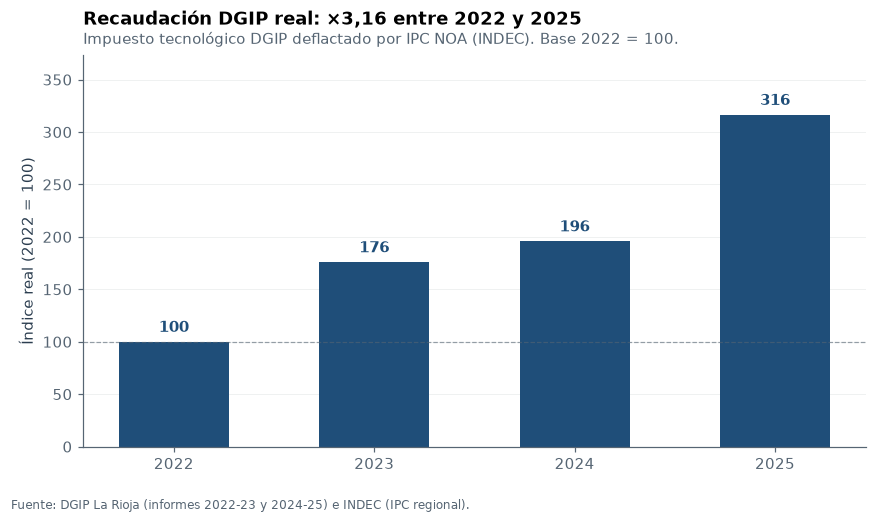

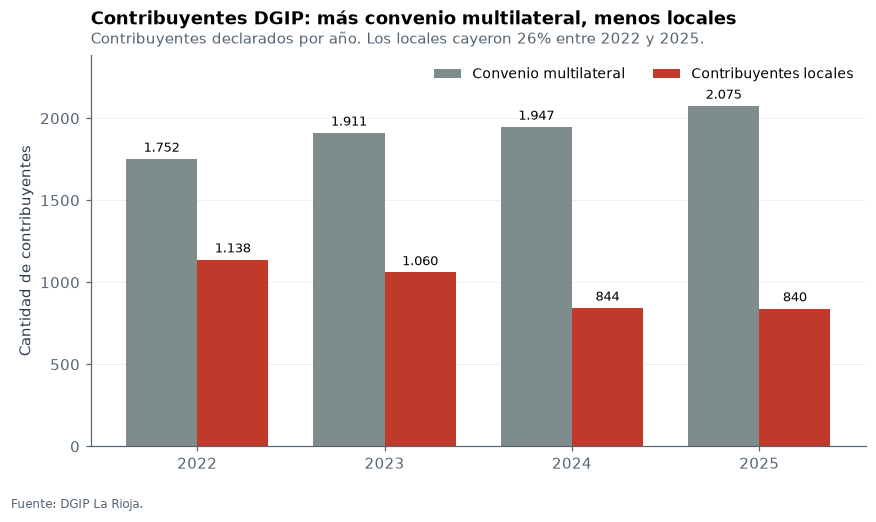

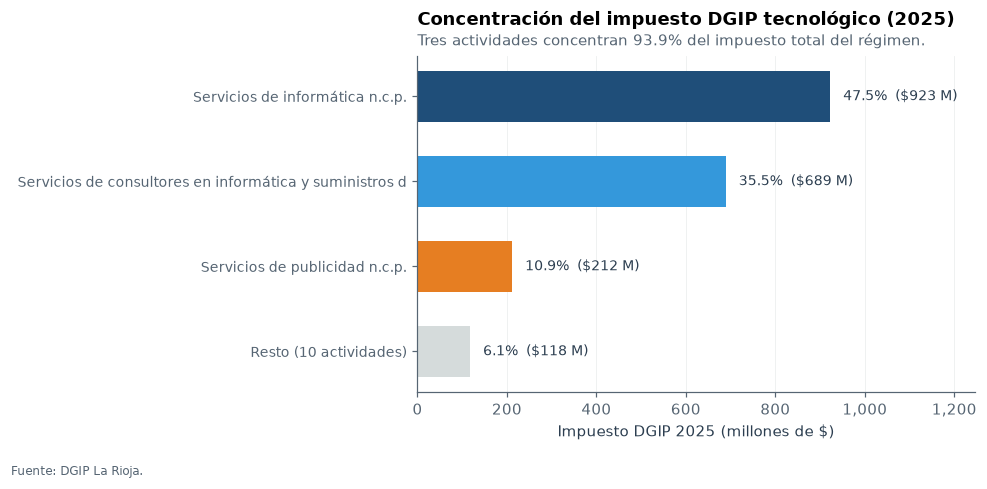

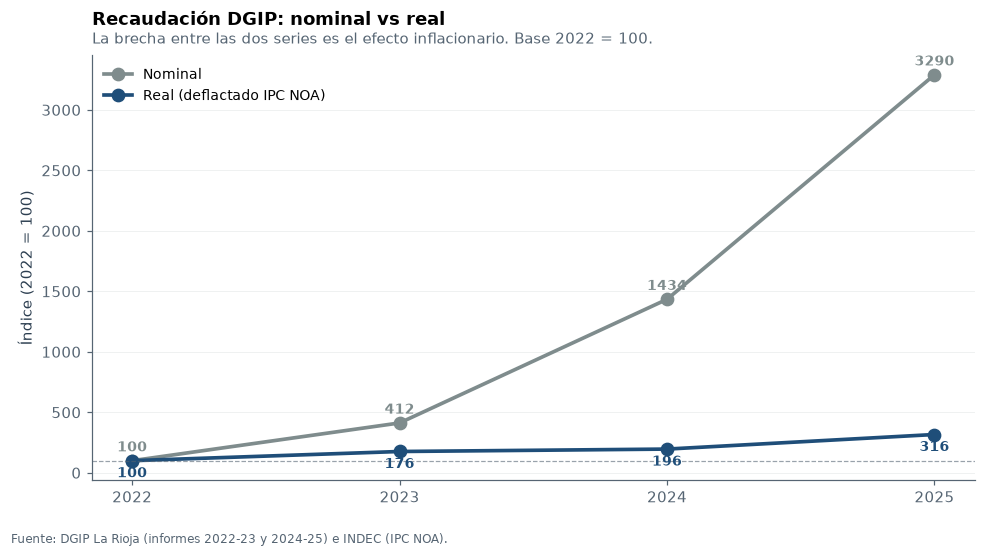

In [8]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.visualizaciones
importlib.reload(src.visualizaciones)

from src.visualizaciones import (
    fig_dgip_real, fig_dgip_contribuyentes,
    fig_dgip_estructura, fig_dgip_nominal_vs_real,
    guardar,
)

guardar(fig_dgip_real()[0], "informe/figuras/D1_dgip_real.png")
guardar(fig_dgip_contribuyentes()[0], "informe/figuras/D2_dgip_contribuyentes.png")
guardar(fig_dgip_estructura(anio=2025)[0], "informe/figuras/D3_dgip_estructura.png")
guardar(fig_dgip_nominal_vs_real()[0], "informe/figuras/D4_dgip_nominal_vs_real.png")

for f in sorted(Path("informe/figuras").glob("D*.png")):
    print(f"  ✅ {f.name}  ({f.stat().st_size/1024:.0f} KB)")

✅ M1 generada


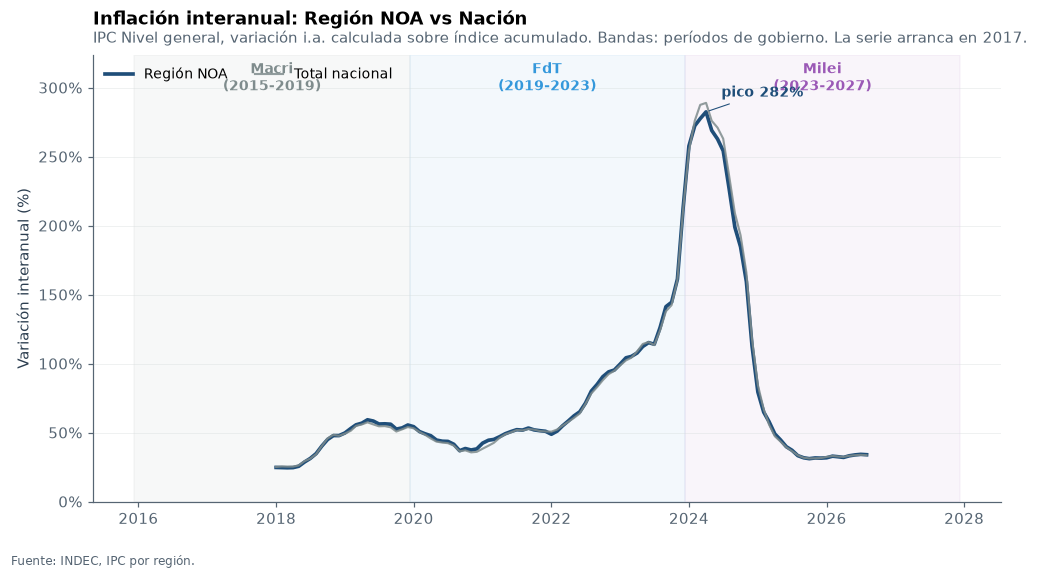

In [9]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.visualizaciones
importlib.reload(src.visualizaciones)

from src.visualizaciones import fig_ipc_gobiernos, guardar

guardar(fig_ipc_gobiernos()[0], "informe/figuras/M1_ipc_gobiernos.png")
print("✅ M1 generada")

  ✅ DASH1_opex_rioja.png  (73 KB)
  ✅ DASH2_opex_benchmark.png  (59 KB)
  ✅ DASH3_empleo.png  (106 KB)
  ✅ DASH4_salario_real.png  (141 KB)
  ✅ DASH5_dgip.png  (72 KB)


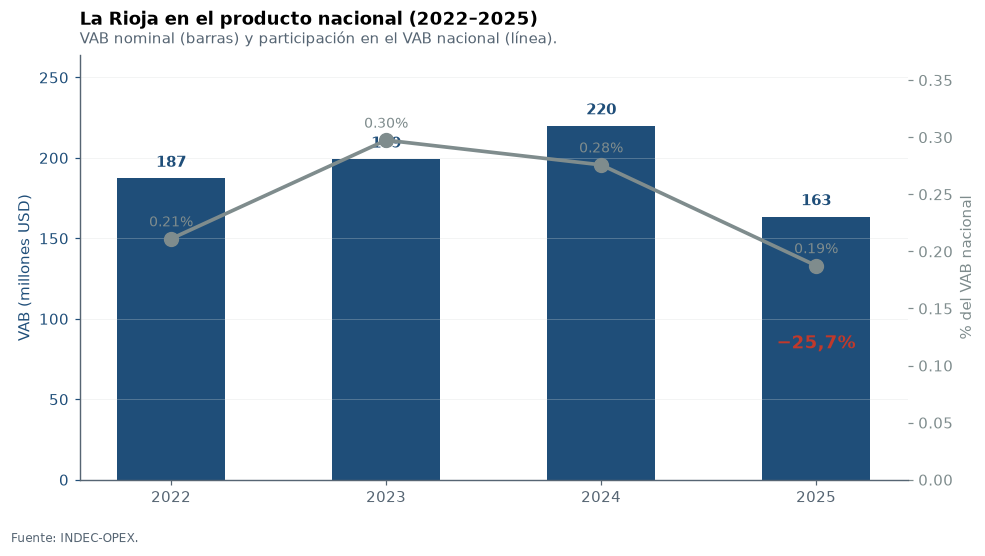

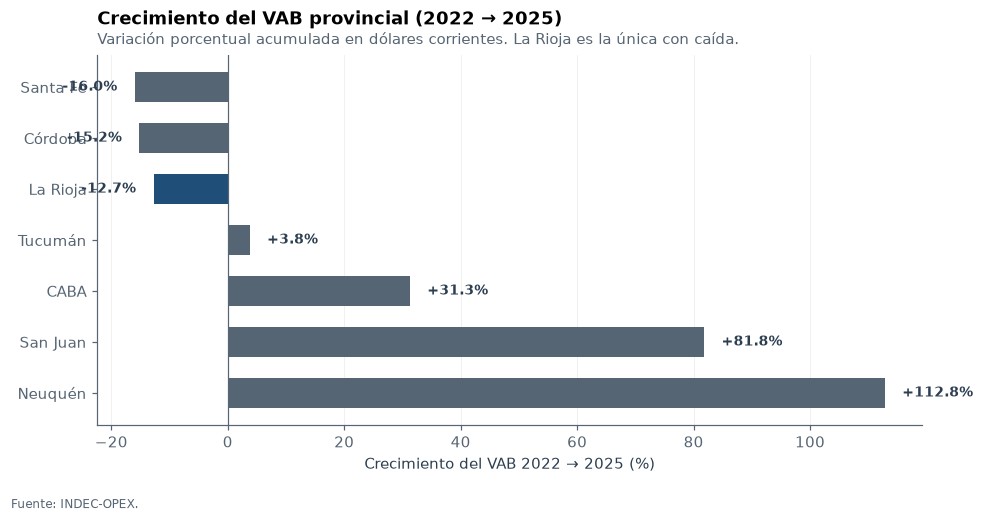

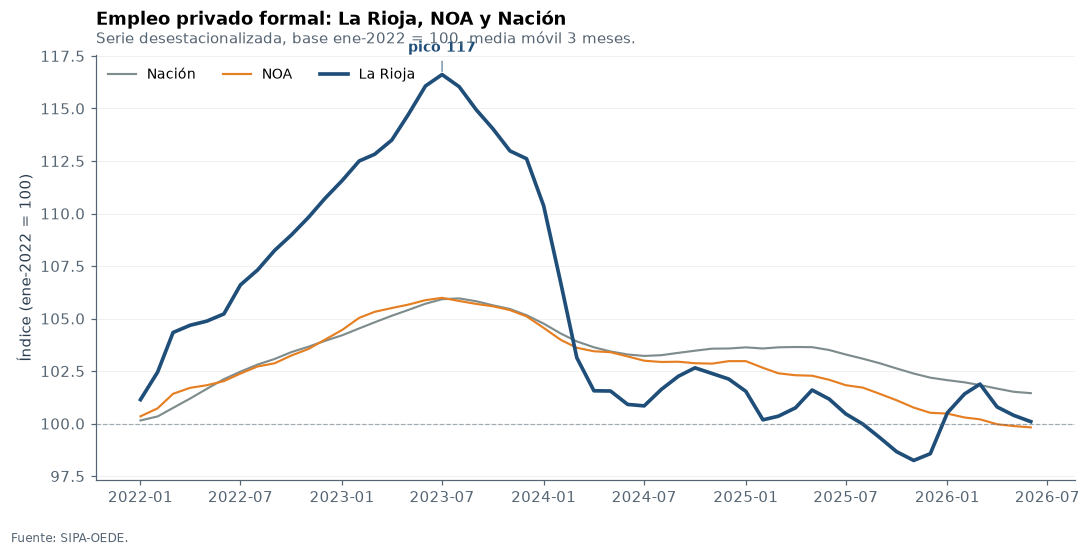

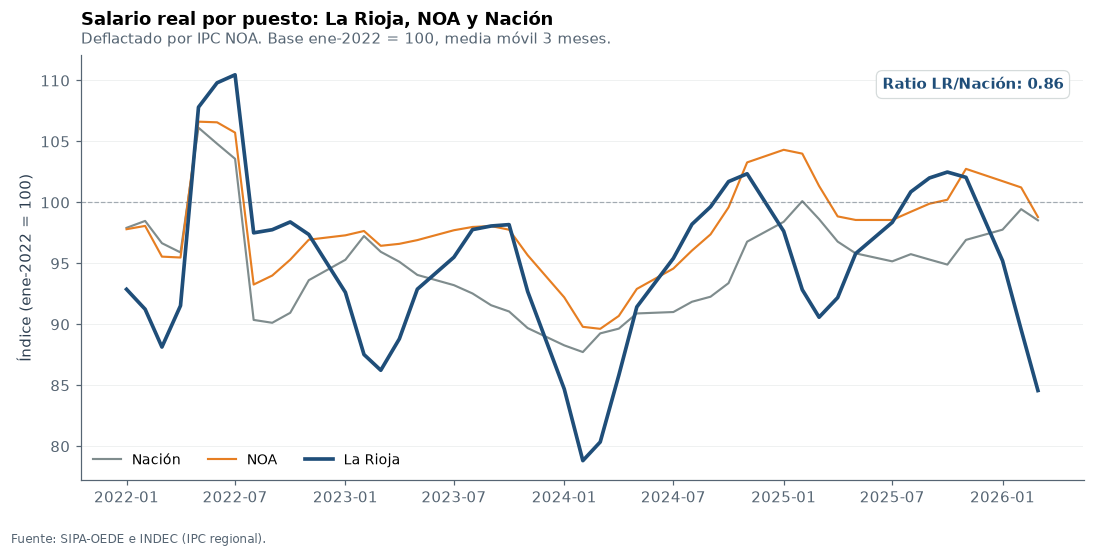

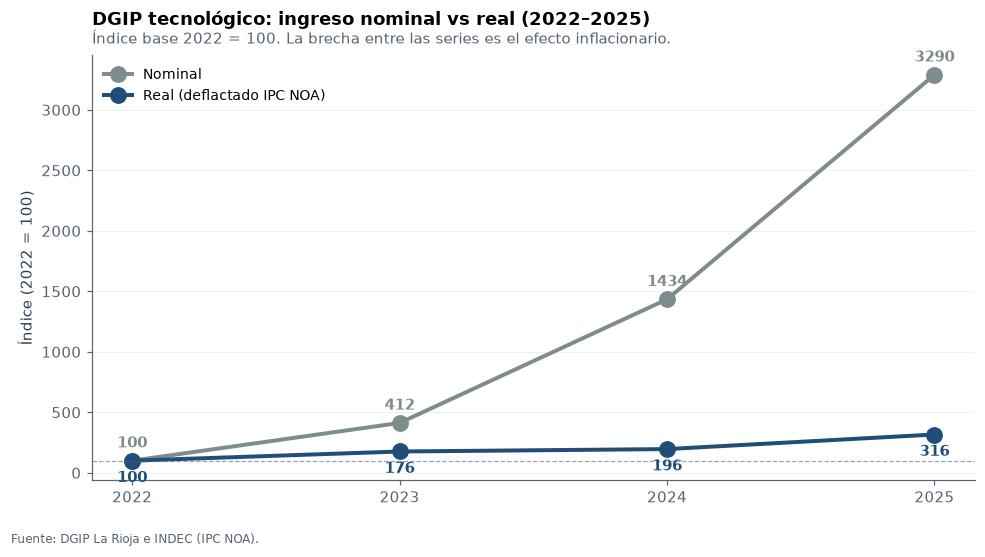

In [2]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import importlib
import src.visualizaciones_dashboard
importlib.reload(src.visualizaciones_dashboard)

from src.visualizaciones_dashboard import (
    dash_opex_rioja, dash_opex_benchmark, dash_empleo_ciclo,
    dash_salario_real, dash_dgip, FIG_DIR_DASH,
)
from src.visualizaciones import guardar

guardar(dash_opex_rioja()[0], FIG_DIR_DASH / "DASH1_opex_rioja.png")
guardar(dash_opex_benchmark()[0], FIG_DIR_DASH / "DASH2_opex_benchmark.png")
guardar(dash_empleo_ciclo()[0], FIG_DIR_DASH / "DASH3_empleo.png")
guardar(dash_salario_real()[0], FIG_DIR_DASH / "DASH4_salario_real.png")
guardar(dash_dgip()[0], FIG_DIR_DASH / "DASH5_dgip.png")

for f in sorted(FIG_DIR_DASH.glob("DASH*.png")):
    print(f"  ✅ {f.name}  ({f.stat().st_size/1024:.0f} KB)")

In [4]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

from src.funciones import cargar_empresas_benchmark

df = cargar_empresas_benchmark(provincias=["La Rioja"])

print("=== Todas las ramas EC (cualquier longitud) ===")
df_ec = df[df["Ramas"].str[:2].isin(["64", "72", "73", "74"])].copy()
print(df_ec[["Ramas", "Descripción"]].drop_duplicates().to_string(index=False))

print(f"\n=== Longitudes de código presentes en EC ===")
print(df_ec["Ramas"].str.len().value_counts().to_string())

print(f"\n=== Todas las ramas disponibles (todas las longitudes) ===")
print(df["Ramas"].drop_duplicates().tolist())

print(f"\n=== Totales EC por año (solo ramas de 2 dígitos) ===")
df_2d = df_ec[df_ec["Ramas"].str.len() == 2]
totales = df_2d.groupby("anio")["empresas"].sum()
print(totales.to_string())

print(f"\n=== Por rama 2d × año ===")
piv = df_2d.pivot_table(index=["Ramas", "Descripción"],
                        columns="anio", values="empresas",
                        aggfunc="sum").fillna(0).astype(int)
print(piv.to_string())

=== Todas las ramas EC (cualquier longitud) ===
Ramas                                                 Descripción
   64                                Telecomunicaciones y correos
   72                                  Actividades de informática
   73                                  Investigación y desarrollo
   74 Servicios jurídicos, contables y otros servicios a empresas

=== Longitudes de código presentes en EC ===
Ramas
2    116

=== Todas las ramas disponibles (todas las longitudes) ===
['A', '1', '2', 'B', '5', 'C', '11', '13', '14', 'D', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', 'E', '40', '41', 'F', '45', 'G', '50', '51', '52', 'H', '55', 'I', '60', '61', '62', '63', '64', 'J', '65', '66', '67', 'K', '70', '71', '72', '73', '74', '75', 'M', '80', 'N', '85', 'O', '90', '91', '92', '93']

=== Totales EC por año (solo ramas de 2 dígitos) ===
anio
1996    147.0
1997    160.0
1998    17

In [5]:
from pathlib import Path
import pandas as pd

for f in sorted(Path("data/raw").glob("*empresas*.xlsx")):
    try:
        xl = pd.ExcelFile(f, engine="openpyxl")
        hojas = xl.sheet_names
        print(f"\n{'='*70}")
        print(f"{f.name}  ({f.stat().st_size/1024:.0f} KB)")
        print(f"{'='*70}")
        print(f"  {len(hojas)} hojas:")
        for h in hojas:
            print(f"    - {h}")
    except Exception as e:
        print(f"\n{f.name}  → ERROR: {e}")


nacional_serie_empresas_2.xlsx  (425 KB)
  14 hojas:
    - Carátula
    - Metodologia
    - Indice
    - C 1
    - C 2
    - C 3
    - C 4
    - C 5
    - C 6
    - C 7
    - C 8
    - C 9
    - C 10
    - Descriptores de actividad

provinciales_serie_empresas.xlsx  (585 KB)
  29 hojas:
    - Carátula
    - Indice
    - Metodología
    - Partidos de GBA
    - Capital Federal
    - Resto de Buenos Aires
    - Catamarca
    - Cordoba
    - Corrientes
    - Chaco
    - Chubut
    - Entre Rios
    - Formosa
    - Jujuy
    - La Pampa
    - La Rioja
    - Mendoza
    - Misiones
    - Neuquen
    - Rio Negro
    - San Juan
    - Salta
    - San Luis
    - Santa Cruz
    - Santa Fe
    - Santiago del Estero
    - Tucuman
    - Tierra del Fuego
    - Hoja1

provinciales_serie_empresas1_2.xlsx  (585 KB)
  29 hojas:
    - Carátula
    - Indice
    - Metodología
    - Partidos de GBA
    - Capital Federal
    - Resto de Buenos Aires
    - Catamarca
    - Cordoba
    - Corrientes
    - Chaco
    

In [6]:
import pandas as pd
from pathlib import Path

f = Path("data/raw/provinciales_serie_empresas.xlsx")

# Ver encabezados y primeras filas de La Rioja
raw = pd.read_excel(f, sheet_name="La Rioja", header=None, nrows=30)
print(raw.to_string())

                                                                         0                                              1     2                 3     4             5     6             7     8             9     10            11    12            13    14            15    16            17    18    19    20    21    22    23    24    25    26    27    28    29    30
0                                                                       NaN                                            NaN   NaN  Volver al índice   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
1                                                                  LA RIOJA                                            NaN   NaN               NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   NaN           NaN   N

In [7]:
import pandas as pd
from pathlib import Path

f = Path("data/raw/provinciales_serie_empresas.xlsx")
raw = pd.read_excel(f, sheet_name="Hoja1", header=None, nrows=30)
print(raw.to_string())

                                                                                                                 0                                              1              2                                                                                                                 3              4              5              6              7              8              9              10             11             12             13             14             15             16             17             18             19             20             21             22             23             24             25             26             27             28             29             30             31             32             33             34             35             36             37             38             39             40             41             42             43             44             45             46             47             48             49             50    

In [8]:
import pandas as pd
from pathlib import Path

f2 = Path("data/raw/provinciales_serie_empresas2_2.xlsx")

for hoja in ["T1", "T2", "T3", "T4", "T5", "T6", "T7"]:
    raw = pd.read_excel(f2, sheet_name=hoja, header=None, nrows=6)
    print(f"\n{'='*72}")
    print(f"  {hoja}")
    print(f"{'='*72}")
    # Solo las 4 primeras columnas, para ver el título y las ramas
    print(raw.iloc[:, :5].to_string())


  T1
                                          0                               1                   2          3                         4
0  Cuadro 1. Empresas por sector - Año 2024                             NaN                 NaN        NaN                       NaN
1                                 Provincia  Agricultura, ganadería y pesca  Minería y petroleo  Industria  Electricidad, gas y agua
2                           Partidos de GBA                            2306                92.0    17226.0                      64.0
3                           Capital Federal                          2532.0                 191    10891.0                       109
4                     Resto de Buenos Aires                         16371.0               124.0     8054.0                       295
5                                 Catamarca                             225                31.0        272                        11

  T2
                                                         

In [9]:
from pathlib import Path
from src.empresas_ec import cargar_provincia, serie_empresas

RUTA = Path("data/raw/provinciales_serie_empresas3_2.xlsx")

provincias = ["La Rioja", "Catamarca", "Jujuy", "Salta",
              "Santiago del Estero", "Tucumán",
              "Córdoba", "Santa Fé", "CABA"]

for p in provincias:
    try:
        df = cargar_provincia(RUTA, p)
        tot = serie_empresas(df).query("anio == 2024")["total_empresas"].iloc[0]
        print(f"{p:25s}  {tot:>8,.0f}".replace(",", "."))
    except Exception as e:
        print(f"{p:25s}  ERROR: {e}")

La Rioja                      3.255
Catamarca                     3.752
Jujuy                         5.345
Salta                        10.412
Santiago del Estero           6.360
Tucumán                      12.086
Córdoba                      58.212
Santa Fé                     53.973
CABA                        136.305


In [10]:
import pandas as pd
from pathlib import Path

RUTA = Path("data/raw/provinciales_serie_empleo_trimestral_4dig_7.xlsx")
xl = pd.ExcelFile(RUTA, engine="openpyxl")
print(f"Hojas ({len(xl.sheet_names)}):")
for h in xl.sheet_names:
    print(f"  - {h}")

Hojas (28):
  - Caratula
  - Indice
  - GBA
  - CABA
  - Resto de Buenos Aires
  - Catamarca
  - Córdoba
  - Corrientes
  - Chaco
  - Chubut
  - Entre Ríos
  - Formosa
  - Jujuy
  - La Pampa
  - La Rioja
  - Mendoza
  - Misiones
  - Neuquén
  - Río Negro
  - Salta
  - San Juan
  - San Luis
  - Santa Cruz
  - Santa Fe
  - Santiago del Estero
  - Tucumán
  - Tierra del Fuego
  - Metodología


In [11]:
import pandas as pd
from pathlib import Path

RUTA = Path("data/raw/provinciales_serie_empleo_trimestral_4dig_7.xlsx")
xl = pd.ExcelFile(RUTA, engine="openpyxl")
print(f"Hojas ({len(xl.sheet_names)}):")
for h in xl.sheet_names:
    print(f"  - {h}")

Hojas (28):
  - Caratula
  - Indice
  - GBA
  - CABA
  - Resto de Buenos Aires
  - Catamarca
  - Córdoba
  - Corrientes
  - Chaco
  - Chubut
  - Entre Ríos
  - Formosa
  - Jujuy
  - La Pampa
  - La Rioja
  - Mendoza
  - Misiones
  - Neuquén
  - Río Negro
  - Salta
  - San Juan
  - San Luis
  - Santa Cruz
  - Santa Fe
  - Santiago del Estero
  - Tucumán
  - Tierra del Fuego
  - Metodología


In [12]:
import pandas as pd
from pathlib import Path

RUTA = Path("data/raw/provinciales_serie_empleo_trimestral_4dig_7.xlsx")

# Ver las primeras 15 filas de La Rioja para entender la estructura
raw = pd.read_excel(RUTA, sheet_name="La Rioja", header=None, nrows=15)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
print(raw.to_string())

                                                                                                                                             0                                                                           1             2             3             4             5             6             7             8             9             10            11            12            13            14            15            16            17            18            19            20            21            22            23            24            25            26            27            28            29            30            31            32            33            34            35            36            37            38            39            40            41            42            43            44            45            46            47            48            49            50            51            52            53            54            55            56           

In [13]:
import re
from pathlib import Path
import pandas as pd
from src.empresas_ec import LEY_27_506

RUTA = Path("data/raw/provinciales_serie_empleo_trimestral_4dig_7.xlsx")
raw = pd.read_excel(RUTA, sheet_name="La Rioja", header=None, engine="openpyxl")

# Encontrar header
header_row = None
for i in range(min(20, len(raw))):
    vals = raw.iloc[i].astype(str).str.strip().str.lower().tolist()
    if "ramas" in vals and any("descrip" in v for v in vals):
        header_row = i
        break
print(f"Header en fila: {header_row}")

df = raw.iloc[header_row + 1:].copy()
df.columns = [str(c).strip() for c in raw.iloc[header_row]]
df = df.rename(columns={df.columns[0]: "rama", df.columns[1]: "descripcion"})
df["rama"] = df["rama"].astype(str).str.strip()
df = df[df["rama"].str.fullmatch(r"\d{3,4}")].copy()

print(f"\nTotal filas con rama 3-4 dígitos: {len(df)}")

# 1. ¿Cuántas filas tiene la rama 7220? (deberían ser 120: 30 años × 4 trimestres)
n7220 = (df["rama"] == "7220").sum()
print(f"\n1. Filas de rama 7220: {n7220}  (esperado: 120)")
print(f"   Si es > 120, hay duplicados.")

# 2. Ver TODAS las filas de rama 7220
print(f"\n2. Todas las filas de rama 7220:")
sub7220 = df[df["rama"] == "7220"]
print(f"   N° de filas: {len(sub7220)}")
print(f"   Descripciones únicas: {sub7220['descripcion'].nunique()}")
print(f"   Primeras 3 descripciones: {sub7220['descripcion'].head(3).tolist()}")

# 3. Ver valores de 7220 en 2024
cols_2024 = [c for c in df.columns if "2024" in str(c)]
print(f"\n3. Valores de rama 7220 en 2024:")
print(f"   Columnas: {cols_2024}")
if not sub7220.empty:
    print(sub7220[["rama", "descripcion"] + cols_2024].to_string(index=False))

# 4. ¿Cuántas filas hay en total con LEY_27_506?
n_ec = df["rama"].isin(LEY_27_506).sum()
print(f"\n4. Filas que matchean LEY_27_506: {n_ec}")
print(f"   Esperado si no hay duplicados: {47 * 120} = 5.640")

# 5. Ver TODAS las ramas que matchean LEY_27_506 y su cantidad de filas
print(f"\n5. Ramas EC y cantidad de filas en el archivo:")
ec_presentes = df[df["rama"].isin(LEY_27_506)]["rama"].value_counts().sort_index()
for r, n in ec_presentes.items():
    print(f"   {r}: {n} filas")

# 6. El máximo valor de una celda EC
cols_trim = [c for c in df.columns if re.search(r"trim", str(c), re.I)]
sub_ec = df[df["rama"].isin(LEY_27_506)]
nums = sub_ec[cols_trim].apply(pd.to_numeric, errors="coerce")
print(f"\n6. Estadísticas de celdas EC (solo valores numéricos):")
print(f"   Máx: {nums.max().max()}")
print(f"   Mediana: {nums.stack().median()}")
print(f"   N° de celdas numéricas: {nums.notna().sum().sum()}")

Header en fila: 6

Total filas con rama 3-4 dígitos: 300

1. Filas de rama 7220: 1  (esperado: 120)
   Si es > 120, hay duplicados.

2. Todas las filas de rama 7220:
   N° de filas: 1
   Descripciones únicas: 1
   Primeras 3 descripciones: ['Servicios de consultores en informática y suministros de programas de informática']

3. Valores de rama 7220 en 2024:
   Columnas: ['1° Trim 2024', '2° Trim 2024', '3° Trim 2024', '4° Trim 2024']
rama                                                                       descripcion 1° Trim 2024 2° Trim 2024 3° Trim 2024 4° Trim 2024
7220 Servicios de consultores en informática y suministros de programas de informática           34           28           27           28

4. Filas que matchean LEY_27_506: 47
   Esperado si no hay duplicados: 5640 = 5.640

5. Ramas EC y cantidad de filas en el archivo:
   2211: 1 filas
   2212: 1 filas
   2219: 1 filas
   2230: 1 filas
   2330: 1 filas
   2423: 1 filas
   2911: 1 filas
   2912: 1 filas
   2913: 1 fila

In [14]:
import re
from pathlib import Path

QMD = Path(r"C:\Users\HP\Documents\Economy\economia_c\informe\informe_completo.qmd")
texto = QMD.read_text(encoding="utf-8")

# Mapeo: label del chunk → (archivo, caption, id_figura)
mapeo = {
    "fig-empleo-comp":  ("F3_empleo_comparado.png",
                          "Empleo registrado privado formal: La Rioja, NOA y Nación. Índice base enero 2019 = 100, serie desestacionalizada. Fuente: SIPA–OEDE."),
    "fig-empleo-zoom":  ("F4_empleo_zoom.png",
                          "Zoom sobre la reversión 2024–2026: La Rioja pierde el diferencial positivo construido entre 2021 y 2024."),
    "fig-sal-real":     ("F6_salario_real.png",
                          "Salario real de La Rioja deflactado por IPC NOA (base 2017 = 100). El piso de 2024 (64,7) es el más bajo desde el inicio de la serie."),
    "fig-ratio-sal":    ("F7_ratio_salarial.png",
                          "Ratio entre el salario promedio de La Rioja y el de la Nación. Un valor de 0,59 indica que un trabajador riojano gana 59 centavos por cada peso del promedio nacional."),
    "fig-emp-serie":    ("F11_empresas_serie.png",
                          "Empresas totales (gris, eje izquierdo) y de Economía del Conocimiento (turquesa, eje derecho) en La Rioja. La fuente no publica datos para 2023."),
    "fig-emp-ramas":    ("F13_empresas_top_ramas.png",
                          "Principales ramas de Economía del Conocimiento en La Rioja, 2024. Valores absolutos y participación sobre el total EC provincial."),
    "fig-empleo-ec-serie": ("F14_empleo_ec_serie.png",
                          "Empleo registrado en empresas de Economía del Conocimiento — La Rioja. Promedio anual de trimestres con dato. Fuente: SIPA–OEDE, definición Ley 27.506."),
    "fig-empleo-ec-part":  ("F15_empleo_ec_participacion.png",
                          "Empleo EC (barras, eje izquierdo) y su participación sobre el empleo provincial (línea, eje derecho). La participación se mantiene estable en el rango 2,1%–2,3%."),
    "fig-elasticidad":     ("F16_elasticidad.png",
                          "Elasticidad: empresas EC vs. empleo EC (índice 2022 = 100). Entre 2022 y 2025 las empresas cayeron −3,5% y el empleo solo −1,7%."),
    "fig-intensidad":      ("F17_intensidad.png",
                          "Intensidad empresarial EC: empresas EC por cada 1.000 empresas totales. La Rioja destacada en turquesa. Fuente: SIPA–OEDE, 2024."),
    "fig-emp-bench":       ("F12_empresas_benchmark.png",
                          "Empresas de Economía del Conocimiento por provincia. Ley 27.506, año 2024. La Rioja destacada en azul."),
}

# Regex que captura un chunk completo con label específico
patron_chunk = re.compile(
    r"(```\{python\}\n"
    r"#\| echo: false\n"
    r"(?:#\|[^\n]*\n)*"
    r"#\| label: {label}\n"
    r"(?:#\|[^\n]*\n)*"
    r"(?:.*?\n)*?"
    r"```)",
    re.MULTILINE | re.DOTALL,
)

for label, (archivo, caption) in mapeo.items():
    # Remover las opciones fig-cap y label del chunk
    def reemplazar(match):
        chunk = match.group(1)
        # Sacar fig-cap y label del chunk
        chunk_limpio = re.sub(r"#\| fig-cap:[^\n]*\n", "", chunk)
        chunk_limpio = re.sub(r"#\| label:[^\n]*\n", "", chunk_limpio)
        # Insertar la referencia de imagen después del chunk
        ref = f"\n![{caption}](figuras/{archivo}){{#{label} fig-align=\"center\"}}\n"
        return chunk_limpio + ref

    patron = re.compile(
        r"(```\{python\}\n"
        r"#\| echo: false\n"
        r"(?:#\|[^\n]*\n)*"
        r"#\| label: " + re.escape(label) + r"\n"
        r"(?:#\|[^\n]*\n)*"
        r"(?:.*?\n)*?"
        r"```)",
        re.MULTILINE,
    )
    texto_nuevo, n = patron.subn(reemplazar, texto)

    if n > 0:
        texto = texto_nuevo
        print(f"[OK] {label} → {archivo}")
    else:
        print(f"[!] No encontré el label {label}")

QMD.write_text(texto, encoding="utf-8")
print(f"\n[OK] Reescrito: {QMD}")

[OK] fig-empleo-comp → F3_empleo_comparado.png
[OK] fig-empleo-zoom → F4_empleo_zoom.png
[OK] fig-sal-real → F6_salario_real.png
[OK] fig-ratio-sal → F7_ratio_salarial.png
[OK] fig-emp-serie → F11_empresas_serie.png
[OK] fig-emp-ramas → F13_empresas_top_ramas.png
[OK] fig-empleo-ec-serie → F14_empleo_ec_serie.png
[OK] fig-empleo-ec-part → F15_empleo_ec_participacion.png
[OK] fig-elasticidad → F16_elasticidad.png
[OK] fig-intensidad → F17_intensidad.png
[OK] fig-emp-bench → F12_empresas_benchmark.png

[OK] Reescrito: C:\Users\HP\Documents\Economy\economia_c\informe\informe_completo.qmd


In [15]:
import inspect
from src import regional

for nombre in ["serie_provincia", "serie_nacional", "serie_noa",
               "cargar_empleo", "cargar_salario", "cargar_ipc_noa",
               "salario_real_propio", "ratio_salarial", "comparar"]:
    fn = getattr(regional, nombre, None)
    if fn is None:
        print(f"{nombre:25s}  NO EXISTE")
        continue
    try:
        sig = inspect.signature(fn)
        print(f"{nombre:25s}  {sig}")
    except Exception as e:
        print(f"{nombre:25s}  ERROR: {e}")

serie_provincia            (provincia: 'str', indicador: 'str', tipo: 'str | None' = None) -> 'pd.Series'
serie_nacional             (indicador: 'str', tipo: 'str | None' = None) -> 'pd.Series'
serie_noa                  (indicador: 'str', tipo: 'str | None' = None) -> 'pd.Series'
cargar_empleo              (tipo: 'str' = 'desestacionalizada') -> 'pd.DataFrame'
cargar_salario             (tipo: 'str' = 'nivel') -> 'pd.DataFrame'
cargar_ipc_noa             () -> 'pd.Series'
salario_real_propio        (niveles: 'Iterable[str]' = ('Nación', 'NOA', 'La Rioja'), base_fecha: 'str | pd.Timestamp' = '2017-01-01') -> 'pd.DataFrame'
ratio_salarial             (numerador: 'str' = 'La Rioja', denominador: 'str' = 'NOA', nominal: 'bool' = True) -> 'pd.DataFrame'
comparar                   (indicador: 'str', niveles: 'Iterable[str]' = ('Nación', 'NOA', 'La Rioja'), empleo_tipo: 'str' = 'desestacionalizada', base_fecha: 'str | pd.Timestamp | None' = None) -> 'pd.DataFrame'


In [16]:
from src import regional

# 1. Empleo — ver esquema
emp = regional.cargar_empleo()
print("=== EMPLEO ===")
print("Columnas:", emp.columns.tolist())
print("Shape:", emp.shape)
print(emp.head(3).to_string())
print()

# 2. Salario — ver esquema
sal = regional.cargar_salario()
print("=== SALARIO ===")
print("Columnas:", sal.columns.tolist())
print("Shape:", sal.shape)
print(sal.head(3).to_string())
print()

# 3. Probar algunos nombres de indicador plausibles
for nombre in ["empleo", "empleo_privado", "empleo_registrado",
               "salario", "salarios", "remuneracion", "nivel"]:
    try:
        s = regional.serie_nacional(nombre)
        print(f"[OK]  indicador='{nombre}' → len={len(s)}")
    except Exception as e:
        print(f"[--]  indicador='{nombre}' → {type(e).__name__}: {e}")

=== EMPLEO ===
Columnas: ['jurisdiccion', 'fecha', 'valor']
Shape: (5225, 3)
  jurisdiccion      fecha     valor
0       Bs. As 2009-01-01  1750.663
1         CABA 2009-01-01  1470.641
2    Catamarca 2009-01-01    30.535

=== SALARIO ===
Columnas: ['jurisdiccion', 'fecha', 'valor']
Shape: (4888, 3)
             jurisdiccion      fecha        valor
0  Buenos Aires (sin GBA) 2010-01-01  3203.292836
1                    CABA 2010-01-01  4159.019541
2               Catamarca 2010-01-01  2812.476156

[OK]  indicador='empleo' → len=209
[OK]  indicador='empleo_privado' → len=188
[OK]  indicador='empleo_registrado' → len=188
[OK]  indicador='salario' → len=188
[OK]  indicador='salarios' → len=188
[OK]  indicador='remuneracion' → len=188
[OK]  indicador='nivel' → len=188


In [ ]:
from pathlib import Path
from src.regional import serie_provincia, serie_nacional, serie_noa, salario_real_propio
from src.visualizaciones import fig_empleo_comparado, fig_salario_real_propio
import inspect

# Ver qué se obtiene de cada función
_emp_lr  = serie_provincia("La Rioja", "empleo")
_emp_nac = serie_nacional("empleo")
_emp_noa = serie_noa("empleo")
_real    = salario_real_propio()

print("=== tipo y estructura ===")
print(f"_emp_lr:   {type(_emp_lr).__name__}, len={len(_emp_lr)}")
print(f"  index[:3]: {_emp_lr.index[:3].tolist()}")
print(f"  head:\n{_emp_lr.head(3)}")
print()
print(f"_real:     {type(_real).__name__}")
if hasattr(_real, "columns"):
    print(f"  cols: {_real.columns.tolist()}")
    print(f"  head:\n{_real.head(3)}")
print()

# Ver firma de las funciones de figura
print("=== firmas ===")
print("fig_empleo_comparado:", inspect.signature(fig_empleo_comparado))
print("fig_salario_real_propio:", inspect.signature(fig_salario_real_propio))
print()

# Probar sin try/except para ver el error real
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

print("=== prueba fig_empleo_comparado ===")
try:
    fig_empleo_comparado(_emp_lr, _emp_noa, _emp_nac,
                         FIG / "test_emp.png")
    print("  [OK]")
except Exception as e:
    print(f"  ERROR: {type(e).__name__}: {e}")

print("=== prueba fig_salario_real_propio ===")
try:
    fig_salario_real_propio(_real, FIG / "test_sal.png")
    print("  [OK]")
except Exception as e:
    print(f"  ERROR: {type(e).__name__}: {e}")